# Section 2: La structuration compacte des données

## Présentation de la section

#### Présentation de la section

## Structuration compacte des données

![Data transport](images/network.png)

Dans cette section, vous apprendrez comment les données transportées sont structurées dans l'internet des objets. Pour les objets ayant souvent une capacité de traitement et une autonomie énergétique limitées, il est impératif que les données soient transmises de façon structurée (pour être interprétées) et compacte (pour économiser de l'énergie).

Les nouveaux formats de données qui font l'internet des objets, tels que JSON et CBOR, doivent donc intégrer ces impératifs.

Nous vous proposons des travaux pratiques qui consisteront à exploiter CBOR pour structurer des données envoyées depuis un objet connecté vers un serveur.

### A la fin de cette semaine, vous serez capable de :





+ expliquer ce qu'est la sérialisation des données,
+ décrire les formats de données JSON et CBOR,
+ émettre des données structurées sur un réseau IoT avec un objet et recevoir ces données sur un serveur.

Bonne semaine !

*L'équipe du MOOC*

## La représentation des données

### Envoyer une donnée - Quiz 2.1

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("k-RhgiwKx2M", width=700, height=394)

#### Envoyer une donnée

# Pourquoi il n'est pas si simple d'envoyer une donnée

Envoyer une donnée sur un réseau n’est pas aussi simple que l’on croit.

Il faut faire la différence entre le format utilisé pour stocker des données dans la mémoire de l'ordinateur et celui employé pour l'envoyer à une autre machine. En effet, chaque machine à sa propre représentation souvent liée aux capacités de leur processeur. Cela est surtout vrai pour les nombres. Ils peuvent être stockés sur un nombre de bits plus ou moins important ou peuvent être représentés en mémoire de manière optimisée pour accélérer leur traitement.

En revanche, la représentation des chaînes de caractères (non accentués) est relativement uniforme car elle se base sur le code ASCII qui est le même pour tous les ordinateurs. Un texte de base est facilement compréhensible par toutes les machines. Une solution serait donc de n'utiliser que des chaînes de caractères.

Par exemple, si l’on veut envoyer l'entier ayant pour valeur 123, il existe plusieurs représentations possibles :

* envoyer une chaîne de caractères ”123” contenant les chiffres du nombre ;
* envoyer la valeur binaire 1111011.

On voit que juste pour transmettre une simple valeur stockée dans la mémoire d'un ordinateur, il existe plusieurs options et évidemment pour que cette valeur soit interprétée de la bonne façon, il faut que les deux extrémités se soient mises d'accord sur une représentation.

Quand on veut transmettre plusieurs valeurs, c'est-à-dire quand on a des données structurées, d'autres problèmes surviennent.

Par exemple : quelle est la taille des blocs que l’on va transmettre ? Comment indiquer la fin de la transmission ? Pour une chaîne de caractères, comment indiquer qu’elle se termine ? Autre exemple : si l'on veut transmettre "12" puis "3", comment faire pour que l'autre extrémité ne comprenne pas "123" ?

Pour que la transmission se fasse correctement, il faut que l’émetteur et le récepteur adoptent les mêmes conventions. Quand il s’agit d’un ensemble de données, il faut être capable de les séparer. Avec les tableurs, une première méthode est possible avec la notation CSV (pour *Comma Separated Values*). Comme son nom l’indique, les valeurs sont séparées par des virgules. Les valeurs sont représentées par des chaînes de caractères. Les textes sont différenciés des valeurs numériques, par l’utilisation de guillemets. Ainsi, 123 sera interprété comme un nombre et ”123” comme un texte.

Si cette représentation est adaptée aux tableurs, elle est relativement pauvre car elle ne permet de représenter que des valeurs sur des lignes et des colonnes. Pour les usages du Web, il a fallu trouver un format plus souple permettant de représenter des structures de données complexes. Évidemment, comme rien n'est simple, il en existe plusieurs et les applications échangeant des données devront utiliser le même.

On voit que l'envoi de la chaîne de caractères ne suffit pas, il faut la formater pour que le récepteur puisse trouver le type de la donnée transmise, qu'un nombre ne soit pas interprété comme une chaîne de caractères, qu'une chaîne de caractères reste une chaîne de caractères même si elle ne contient que des chiffres.

**Quiz : Quiz 2.1**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1-Combien faut-il au minimum d'octets pour représenter en binaire la valeur 123 ?**"))
q0_w = widgets.Text(layout=widgets.Layout(width="40%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(_num_ok(q0_w.value, "1"), "Un octet permet de représenter les nombres de 0 à 255. Donc, un seul octet suffit."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2-Combien faut-il de caractères pour transmettre cette valeur ?**"))
q1_w = widgets.Text(layout=widgets.Layout(width="40%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(_num_ok(q1_w.value, "3"), "Chaque chiffre va compter comme un caractère. \"123\" en comporte 3."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)



### La sérialisation - Quiz 2.2

#### La sérialisation

# La sérialisation

Sous ce nom barbare se cache la méthode utilisée pour transmettre des données d’un ordinateur à un autre. Une donnée peut être simple (un nombre, un texte) ou plus complexe (un tableau, une structure...). Elle est stockée dans la mémoire de l'ordinateur suivant une représentation qui lui est propre. Par exemple, la taille des entiers peut varier d'une technologie de processeur à une autre, l'ordre des octets dans un nombre peut aussi être différente ([little et big endian](https://fr.wiktionary.org/wiki/little-endian)). Pour des structures complexes comme les tableaux, les éléments peuvent être rangés à différents emplacements de la mémoire.

La [sérialisation](https://fr.wikipedia.org/wiki/S%C3%A9rialisation) consiste à transformer une structure de données en une séquence qui pourra être transmise sur le réseau, stockée dans un fichier ou une base de données. L'opération inverse, consistant à reconstruire localement une structure de données, s'appelle désérialisation.

![](images/serialisation001.png)

*[Crédit image : Jean-Michel DOUDOUX](https://jmdoudoux.developpez.com/cours/developpons/java/chap-serialisation.php)*

Il existe plusieurs formats pour sérialiser les données. Ils peuvent être binaires mais ceux généralement utilisés sont basés sur des chaînes de caractères. En effet, la représentation ASCII définissant les caractères de base et codée sur 7 bits est commune à l'ensemble des ordinateurs. L'autre avantage du code ASCII est qu'il est facilement lisible et simplifie la mise au point des programmes.

Wikipédia donne ce tableau des codes ASCII datant de 1972 (une éternité en informatique) et recolorisé par nos soins.

![](images/Capture20.png)

Les caractères en orange ne sont pas imprimables. Ils permettent de contrôler la communication des données ou de gérer l'affichage en revenant à la ligne. On les reconnait car la séquence binaire commence par 00X XXXX. On rappelle que le code ASCII est sur 7 bits ; le bit supplémentaire (bit de parité) conduisant à 1 octet était utilisé pour détecter des erreurs de transmission. Les valeurs de 0x30 à 0x39 codent les chiffres de 0 à 9.

#### Python: Hexlify

## Hexlify

En Python, il existe le module [binascii](https://docs.python.org/fr/3/library/binascii.html) très pratique qui permet de convertir une séquence binaire en une chaîne de caractères ou inversement :

* hexlify prend un tableau d'octets et le convertit en une chaîne de caractères hexadécimaux plus lisible pour les spécialistes. Cela permet de visualiser n'importe quelle séquence de données.
* unhexify fait l'inverse. Il prend une chaîne de caractères et la convertit en un tableau d'octets. Cela peut vous faciliter la programmation car, dans votre code, il est plus facile de manipuler des chaînes de caractères.

Dans la suite du cours, nous l'utiliserons pour manipuler des identifiants. Par exemple, ce bout de code illustre l'utilisation de ces fonctions :

```python
mac = lora.mac()
print ('devEUI: ', binascii.hexlify(mac))
# create an OTAA authentication parameters
app_eui = binascii.unhexlify('70 B3 D5 7E D0 03 3A E3'.replace(' ',''))
```

La fonction lora.mac() retourne un tableau d'octets. La fonction hexlify ligne suivante le convertit en chaîne de caractères pour un affichage plus propre.

Inversement, nous devons affecter une séquence binaire à la variable app_eui. Nous mettons cette séquence hexadécimale en chaîne de caractères. Les espaces offrent plus de lisibilité. Ils sont retirés par la méthode replace et le résultat est converti en binaire.

#### Exemple d'utilisation de hexlify

Soit le programme Python3 suivant :

```python
import binascii
val = b"\x01\x0234"
ser = binascii.hexlify (val)
print (val, ser)
```

qui affecte à la variable val un tableau d'octets. On rappelle que \xAB permet de coder un octet ayant pour valeur hexadécimal 0xAB.

**Quiz : Quiz 2.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**On rappelle que la fonction len() retourne la taille d'une variable.**"))
q0_w = widgets.Text(layout=widgets.Layout(width="40%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(_num_ok(q0_w.value, "4"), ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2-Quelle est la longueur en octets de la variable ser ?**"))
q1_w = widgets.Text(layout=widgets.Layout(width="40%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(_num_ok(q1_w.value, "8"), ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**3-Pourquoi cette différence ?**"))
q2_w = widgets.RadioButtons(options=['Python rajoute des informations cachées pour gérer les chaînes de caractères.', 'Les octets sont stockés dans des mots de 16 bits.', 'Il faut deux caractères pour représenter un octet.', 'Les valeurs sont répétées plusieurs fois pour éviter les erreurs de transmission.'], description="", layout=widgets.Layout(width="90%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value == 'Il faut deux caractères pour représenter un octet.', ""))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)



#### Base 64

## Base 64

Le passage d'une séquence binaire à une chaîne de caractères ASCII en représentant les valeurs conduit à un doublement du volume. Chaque bloc de 4 bits va conduire à produire un octet correspondant au caractère d'un chiffre ou d'une lettre de A à F. Le reste des codes n'est pas utilisé.

Le codage base64 offre un meilleur rendement en utilisant 64 bits pour coder les valeurs. Un dictionnaire fait la correspondance entre 64 valeurs et un caractère ASCII. Cependant, si l'on veut coder 4 octets, soit 32 bits, il faudra 5 blocs de 6 bits, et il y aura deux bits restants. Le symbole = indique que 2 bits sont ajoutés à la fin du codage. Donc, dans notre cas, il faudra ajouter deux symboles = comme le montre la figure ci-dessous :

![](images/Capture21.png)

On notera que pour les petites séquences, ce codage n'est pas meilleur que la transformation de la séquence hexadécimale en chaîne de caractères. Ici, il faut 8 caractères pour coder 4 octets.

Il existe beaucoup d'outils en ligne pour faire les conversions entre ces différentes représentations, comme le site [www.asciitohex.com](https://www.asciitohex.com/)

**Quiz : Quiz 2.2**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**4-Donnez la valeur en hexadécimal de la séquence base64 3q2+7w==, utilisez le format de hexlify (par exemple : 90ABCD)**"))
q0_w = widgets.Text(layout=widgets.Layout(width="40%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value.strip().lower() == "DEADBEEF".strip().lower(), ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



#### Python et base64

En Python3, le module [base64](https://docs.python.org/fr/3/library/base64.html) permet de faire ces conversions.  Ce module est un peu susceptible sur les types de données à utiliser.

```python
import base64
val = b"\x01\x0234"
ser = base64.b64encode(val)
print (ser)
print (ser.decode())
ori = base64.b64decode(ser)
print (ori)
```

qui donne à l’exécution :

```
b'AQIzNA=='
AQIzNA==
b'\x01\x0234'
```

À noter que l'utilisation du ser.decode(), ligne 6, pour transformer une chaîne d'octets en chaîne de caractères, peut être utilisé dans certains cas.

### HTML et XML

#### HTML et XML

![](/static/pngegg__1_.png)

La sérialisation en chaînes de caractères (par exemple en Python via la commande hexlify) ou en base64 concerne surtout des données binaires. Mais la donnée peut être aussi structurée, par exemple la page d'un tableur. Il faut donc formater le document pour éviter une fusion des différents champs. Le format CSV (*Comma Separated Values*), comme son nom l'indique, sépare les données par des virgules (*comma* en anglais). Mais si ce format s'applique bien aux données d'un tableau, c'est-à-dire un tableau de lignes et de colonnes, il est très limité pour représenter une information telle que la mise en forme d'une page Web.

HTML (*Hyper Text Markup Language*), sans entrer dans les détails, définit un format où les champs sont repérés par un balisage.  Une balise de début est un mot clé entre <> et, pour une balise de fin, le mot clé est précédé du caractère /. Par exemple, avec le balisage, le premier paragraphe est formaté de cette manière :

![](images/Capture22.png)

Les balises peuvent aussi prendre des arguments, comme la balise span dans l'exemple précédent. Ainsi, si l'on regarde une page Web :

![](images/Capture23.png)

le navigateur est capable de l'analyser pour trouver les URI qu'elle contient. La balise img indiquant qu'il s'agit d'une image, le client peut interroger le serveur pour l'afficher à l'écran. Ce format structuré de sérialisation nous permet de mettre en place une caractéristique de REST, c'est-à-dire les liens entre ressources.

![](images/1200px-Xml_logo.svg.png)

Si HTML est dédié au formatage à l'écran de données textuelles et à la navigation sur le Web, XML (*eXtensible Markup Language*), défini par le W3C, est un format d’échange entre deux applications. Par exemple, pour échanger les notes des étudiants entre la plate-forme FUN et une autorité de certification, on pourrait utiliser le format suivant :

```
<etudiant>
<prenom>John</prenom>
<nom>Deuf</nom>
<note>18</note>
</etudiant>
```

Il est facile en lisant l'exemple de trouver le prénom, le nom et la note de l'étudiant. On peut noter qu'il n'y a pas de différence entre la note et le nom de l'élève. Il s'agit de caractères.

S'il est syntaxiquement correct, rien ne dit que le créateur fournit quelque chose de correct qui pourra être interprété par une autre instance.  XML peut inclure une grammaire ou un schéma qui est utilisé pour valider que les informations représentées dans le fichier sont non seulement syntaxiquement conformes au langage XML, mais aussi conformes au schéma. Ce schéma va décrire les champs attendus et leur type (texte, nombre...). Vous pouvez accéder à ce [cours](https://www.irif.fr/~carton/Enseignement/XML/Cours/Schemas/index.html) si vous voulez en savoir plus sur les schémas XML.

Du point de vue de l’internet des objets, même si le XML pourrait être un bon candidat pour l’échange d’informations, il est un format trop lourd et donc énergivore. On peut noter que pour envoyer une note sur 20 qui, dans l'absolu, prendrait 6 bits, on transmet <note>18</note>, soit 15 caractères.

### JSON

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("IhZ9w6jWnq8", width=700, height=394)

#### JSON

![RÃ©sultat de recherche d'images pour "json"](https://www.djerfy.com/wp-content/uploads/2016/03/json_logo-555px.png)

JSON (*JavaScript Object Notation*) offre un moyen de structurer l’information de manière plus compacte que XML. JSON s’impose comme le langage commun pour échanger les informations. À l’origine, JSON était utilisé par Javascript pour échanger des informations ; par exemple, pour afficher en temps réel l’évolution des cours de la bourse ou pour afficher des graphiques dynamiques sur l’écran de l’utilisateur.

JSON [[RFC 8259](https://tools.ietf.org/html/rfc8259)] est un format d’échange simple. Il définit 4 types de données :

* nombre,
* texte,
* tableau,
* objet.

Les nombres sont composés de chiffres et peuvent être positifs, négatifs, entiers ou flottants.

Le texte est délimité par des guillemets simples ou doubles.

Les tableaux sont des listes d’éléments séparés par des virgules et entourés de crochets.

L’objet est une liste de paires composées d’une clé et d’une valeur. La clé est une chaîne de caractères et la valeur peut être de n’importe quel type. La clé doit être unique à l’intérieur d’un objet, et référence entièrement la valeur qui la suit. Le couple clé - valeur est séparé par le caractère 2 points  (:). Les éléments de l’objet sont séparés par des virgules. L'objet est délimité par des accolades.

Exemples :

+ [1, 2, 3, 4] est un tableau qui contient 4 nombres ;
+ [1, ”2”, ”34”] est un tableau contenant un nombre et deux chaines de caractères ;
+ [1, [2, 3 , ”4”]] est un tableau de deux éléments dont le second est également un tableau de 3 éléments ;
+ { ”couleur” : [34, 16, 3]} est un objet qui contient un élément et la valeur est un tableau ;
+ { ”name” : ”bob”, ”age” : 30} est un objet qui contient deux éléments référencés par les chaines de caractères (ou index)  ”name” et ”age”.

L’ordre dans lequel sont placés les éléments est indifférent. {”age” : 30, ”name” : ”bob”} est équivalent au dernier exemple.

Cela impose que l’index utilisé pour accéder à une valeur doit être unique dans la structure objet {”name” : ”bob”, ”name” : ”alice”} est interdit.

Le listing suivant donne un exemple de structure JSON tirée de la RFC 8259. Elle contient un objet JSON avec une seule clé ”Image”. La valeur de cette clé est une autre structure qui contient 6 éléments.

```
{
"Image": {
"Width": 800,
"Height": 600,
 "Title": "View from 15th Floor",
"Thumbnail": {
"Url": "http://www.example.com/image/481989943",
"Height": 125,
"Width": 100
},
"Animated" : false,
"IDs": [11, 943, 234, 38793]
}
}
```

Le balisage par clé est un élément fondamental dans la structure des données. Il est primordial d'être cohérent et d'assurer une concordance entre émetteur et récepteur sur l'intitulé de la clé pour pouvoir récupérer l'information voulue. De la même façon, il faut s'accorder sur les unités de mesure : une interprétation d'une mesure en centimètre alors qu'elle est en pixel peut être désastreux ; c'est un problème d'interopérabilité.

JSON est facilement exploitable dans d’autres langages. Par exemple en Python, le module JSON peut être utilisé pour convertir une structure JSON qui est une chaîne ASCII en une représentation interne Python. Les tableaux sont convertis en listes et les objets en dictionnaires.

Le programme example_json.py

```python
import json
import pprint
struct_python = {
"Image": {
"Width": 800,
"Height": 600,
 "Title": "View from 15th Floor",
"Thumbnail": {
"Url": "http://www.example.com/image/481989943",
"Height": 125,
"Width": 100
},
"Animated" : False,
"Copyright" : None,
"IDs": [0x11, 0x943, 234, 38793],
"Title": "Empty picture"
}
}
print (struct_python)
pprint.pprint(struct_python)
struct_json = json.dumps(struct_python)
print(struct_json)
struct_python2 = json.loads(struct_json)
pprint.pprint (struct_python2)
```

reprend la structure précédente. La première structure est une structure Python. On peut voir que les valeurs pour "Animated" et "Copyright" sont les mots clé Python False (avec un F majuscule) et None. Le programme affiche deux fois cette valeur avec la commande standard *print* puis avec le module *pprint* pour avoir un affichage plus lisible. On peut remarquer que l'ordre d'affichage des clés est différent. Comme "Title" était défini deux fois, seul le dernier est conservé dans la structure Python.

Grâce à la fonction dumps du module json, la variable struct_python est transformée en JSON. Les mots clé False et None sont remplacés par false et null.

Le programme affiche une chaîne de caractères.

Pour le retransformer, de JSON en variable Python, on utilise la fonction inverse loads qui traduit une chaîne de caractères en variable Python, Les autres langues de programmation possèdent également leur propre bibliothèque pour effectuer la traduction.

Par rapport à XML, JSON est beaucoup plus permissif et manque de formalisme pour décrire la structure. JSON-LD (Linked Data) défini par le W3C renforce l’interopérabilité de JSON en introduisant des clés spécifiques décrivant la structure des données, une référence aux unités, etc. Nous verrons ces concepts dans la suite du cours.

### CBOR

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("thSWuJ-1ld0", width=700, height=394)

#### CBOR

### CBOR

JSON et CBOR sont tous les deux des modes de codage de la donnée.

JSON introduit une notation très flexible permettant de représenter toutes les structures de données. Le choix de [l'ASCII](https://fr.wikipedia.org/wiki/American_Standard_Code_for_Information_Interchange) rend ce format universel et n'importe quel ordinateur pourra le comprendre. Mais l'utilisation de l'ASCII ne permet pas de transmettre de manière optimale l'information sur un réseau. Quand les réseaux ont un débit raisonnable, cela ne pose pas de problème. Quand on en vient à l'internet des objets, il faut prendre en compte la capacité de traitement limité des équipements et la faible taille des messages échangés.

Ainsi, en ASCII, la valeur 123 est codée sur 3 octets (un octet par caractère) tandis qu'en binaire elle n'occuperait qu'un seul octet : 0111 1011.

[CBOR](http://www.bortzmeyer.org/7049.html) (*Concise Binaire Object Representation*), défini dans le [RFC 7049](https://tools.ietf.org/html/rfc7049), permet de représenter les structures de JSON mais suivant une représentation binaire. Comme nous le verrons par la suite, si CBOR est complètement compatible avec JSON, il est possible de représenter d'autres types d'information très utiles dans l'internet des objets.

La taille de l'information est réduite et le traitement simplifié. Il faut savoir un peu jongler avec la représentation binaire mais cela reste basique.

CBOR définit **8 types majeurs** qui sont représentés par les 3 premiers bits d'une structure CBOR. Ces types majeurs ont donc des valeurs comprises entre 0 et 7 (000 à 111 en binaire).

![](images/cbor1.png)

Les cinq bits suivants contiennent soit une valeur soit une longueur indiquant combien d'octets sont nécessaires pour coder la valeur. CBOR offre ainsi des optimisations qui permettent de réduire la longueur totale de la structure des données comme nous le verrons par la suite en étudiant les différents types majeurs.

#### CBOR en Python

### CBOR en python

Les exemples qui vont suivre peuvent être testés sur votre ordinateur avec Python3. Si une erreur se produit au moment de la définition du module cbor2, vous devez l'installer sur votre ordinateur en tapant la commande :

pip3 install cbor2

#### Type Entier Positif

### Type Entier Positif

JSON ne fait pas de différence entre les nombres, entiers, décimaux, positifs ou négatifs. CBOR réintroduit une distinction pour optimiser la représentation.

Le premier type majeur correspond aux entiers positifs. Il est codé par 3 bits à 0 ; les 5 bits suivants finissent l'octet et, suivant leur valeur, vont avoir une signification différente :

+ de 0 à 23, il s'agit de la valeur de l'entier à coder ;
+ 24 indique que l'entier est codé sur 1 octet qui sera codé dans l'octet suivant ;
+ 25 indique que l'entier est codé sur 2 octets qui seront codés dans les deux octets suivants ;
+ 26 indique que l'entier est codé sur 4 octets qui seront codés dans les quatre octets suivants ;
+ 27 indique que l'entier est codé sur 8 octets qui seront codés dans les huit octets suivants.

On peut noter qu'il n'y a pas de surcoût pour coder un entier de 0 à 23. Ainsi, la valeur 15 sera codée 0x0F (000-0 1111) tandis que, pour toutes les autres valeurs supérieures, le surcoût ne sera que d'un octet. 100 sera codé 000-1 1000 (11000 correspond à 24) suivi de la valeur 100 (0110 0100).

Le programme cbor-integer-ex1.py va afficher les puissances de 10 entre 100 et 1018.

```python
import cbor2 as cbor
v = 1
for i in range (0, 19):
c = cbor.dumps(v)
print ("{0:3} {1:30} {2}".format(i, v, c.hex()))
v \*= 10
```

Le programme importe le module cbor2 et le renomme pour plus de simplicité cbor.

Le module cbor utilise comme pour JSON la méthode dumps pour sérialiser une structure interne de Python dans la représentation demandée. À l'inverse, la méthode loads sera utilisée pour importer une structure CBOR dans une représentation interne.

La boucle permet d'avoir les multiples de 10 (variable v). Le print en ligne 7 permet d'aligner les données pour que l'affichage soit plus clair ; entre les accolades, le premier chiffre indique la position dans les arguments de format ; le second, après le :, le nombre de caractères. Par exemple, {1:30} indique l'argument v de format affiché sur 30 caractères.

Pour exécuter le programme :

* ouvrez un terminal,
* allez dans le répertoire PLIDO/cbor-example,
* lancez le programme avec la commande "python3.9 cbor-integer-ex1.py" (attention python3 tout court ne fonctionne pas).

![](images/cbor.gif)

Le programme donne le résultat suivant :

  0                              1 01  
  1                             10 0a  
  2                            100 1864  
  3                           1000 1903e8  
  4                          10000 192710  
  5                         100000 1a000186a0  
  6                        1000000 1a000f4240  
  7                       10000000 1a00989680  
  8                      100000000 1a05f5e100  
  9                     1000000000 1a3b9aca00  
 10                    10000000000 1b00000002540be400  
 11                   100000000000 1b000000174876e800  
 12                  1000000000000 1b000000e8d4a51000  
 13                 10000000000000 1b000009184e72a000  
 14                100000000000000 1b00005af3107a4000  
 15               1000000000000000 1b00038d7ea4c68000  
 16              10000000000000000 1b002386f26fc10000  
 17             100000000000000000 1b016345785d8a0000  
 18            1000000000000000000 1b0de0b6b3a7640000

On voit facilement que les valeurs 1 et 10 sont codées sur 1 octet ; que 100 est codé sur 2 octets tandis que les valeurs 1 000 et 10 000 sont codées sur 3 octets. Les valeurs entre 100 000 et 1 000 000 000 nécessitent 5 octets et les suivantes 9 octets.

La taille de la représentation s'adapte à la valeur. Ainsi, il n'est pas nécessaire de définir une taille fixe pour coder une donnée.

On peut aussi noter que comme le type majeur est sur 3 bits, ce type peut être reconnu car il commence par la valeur "0" ou "1".

#### Type Entier Négatif

### Type Entier Négatif

Le type majeur entier négatif est à peu près similaire à l'entier positif. Le type majeur est 001 et le codage de la valeur se fait sur la valeur absolue du nombre à laquelle on retranche 1. Cela évite deux codes différents pour les valeurs 0 et -0.

Ainsi, pour coder -15, on va coder la valeur 14, ce qui donne en binaire 001-1 1110. Ainsi, -24 peut également être codé sur 1 octet tandis que +24 sera codé sur 2 octets.

Le programme cbor-integer-ex2.py reprend le même code mais pour des puissances de 10 négatives.

Lancez le programme avec la commande "python3.9 cbor-integer-ex2.py"

  0                             -1 20  
  1                            -10 29  
  2                           -100 3863  
  3                          -1000 3903e7  
  4                         -10000 39270f  
  5                        -100000 3a0001869f  
  6                       -1000000 3a000f423f  
  7                      -10000000 3a0098967f  
  8                     -100000000 3a05f5e0ff  
  9                    -1000000000 3a3b9ac9ff  
 10                   -10000000000 3b00000002540be3ff  
 11                  -100000000000 3b000000174876e7ff  
 12                 -1000000000000 3b000000e8d4a50fff  
 13                -10000000000000 3b000009184e729fff  
 14               -100000000000000 3b00005af3107a3fff  
 15              -1000000000000000 3b00038d7ea4c67fff  
 16             -10000000000000000 3b002386f26fc0ffff  
 17            -100000000000000000 3b016345785d89ffff  
 18           -1000000000000000000 3b0de0b6b3a763ffff

####

#### Type Séquence binaire ou Chaîne de caractères

### 

#### Type Séquence binaire ou Chaîne de caractères

Les séquences binaires et les chaînes de caractères ont le même comportement. Le type majeur est respectivement 010 et 011. Il est suivi par la longueur de la séquence ou de la chaîne. Le même type de codage que pour les entiers est utilisé :

* si la longueur est inférieure à 23, elle est codée dans la suite du premier octet. On trouve ensuite le nombre d'octets ou de caractères correspondant à cette longueur ;
* si la longueur peut être codée dans 1 octet (donc inférieure à 255), la suite du premier octet contient 24 puis l'octet suivant contient la longueur suivie du nombre d'octets ou de caractères correspondant.
* si la longueur peut être codée dans 2 octets (donc inférieure à 65535), la suite du premier octet contient 25 puis l'octet suivant contient la longueur suivie du nombre d'octets ou de caractères correspondant.
* si la longueur peut être codée dans 4 octets, la suite du premier octet contient 26 puis l'octet suivant contient la longueur suivie du nombre d'octets ou de caractères correspondant.
* si la longueur peut être codée dans 8 octets, la suite du premier octet contient 27 puis l'octet suivant contient la longueur suivie du nombre d'octets ou de caractères correspondant.

Ce codage est aussi assez optimal. Il est rare d'envoyer plus de 23 caractères.

Le programme cbor-string.py montre la représentation de chaînes de caractères de longueur croissante ainsi qu'une séquence binaire.

```python
import cbor2 as cbor
for i in range (1, 10):
c = cbor.dumps("LoRaWAN"\*i)
print ("{0:3} {1}".format(i, c.hex()))
bs = cbor.dumps(b"\x01\x02\x03")
print (bs.hex())
```

La variable i prend des valeurs de 1 à 9. La multiplication d'une chaîne de caractères par un entier (ligne 4) indique le nombre de répétitions de celle-ci. La variable bs contient la représentation en CBOR d'un tableau d'octets Python (représenté par le caractère "b" avant les guillemets).

Lancez le programme avec la commande "python3.9 cbor-string.py"

Le résultat est le suivant :

  1 **67**4c6f526157414e  
  2 **6e**4c6f526157414e4c6f526157414e  
  3 **75**4c6f526157414e4c6f526157414e4c6f526157414e  
  4 **781c**4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e  
  5 **7823**4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e  
  6 **782a**4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e  
  7 **7831**4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e  
  8 **7838**4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e  
  9 **783f**4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e4c6f526157414e  
43010203

Jusqu'à 3 répétitions de la chaine de caractères "LoRaWAN", le codage de la longueur est optimal (codé sur 2 octets).

#### Type tableau

### Type tableau

Le type tableau va regrouper un ensemble d'éléments. Chacun de ces éléments étant une structure CBOR, la seule information nécessaire pour connaitre le début et la fin d'un tableau est son nombre d'éléments. Le type majeur est 100. Il existe deux méthodes pour coder la longueur d'un tableau :

* si celle-ci est connue au moment du codage, il suffit de l'indiquer avec un codage identique à celui utilisé pour indiquer la longueur d'une chaîne de caractères ;
* si celle-ci n'est pas connue au moment du codage, il existe un code spécial pour indiquer la fin du tableau. Nous en reparlerons par la suite.

Le programme cbor-array.py donne quelques exemples de codage de tableau :

* [1,2,3,4] devient 8401020304. On peut deviner la structure du message CBOR : 0x84 indique un tableau de 4 éléments (attention le décodage n'est pas toujours aussi simple). Les 4 éléments sont des entiers inférieurs à 23 ;
* [1,[2, 3], 4] devient 830182020304. Il s'agit d'un tableau de 3 éléments dont le deuxième est un tableau de deux éléments ;
* [1000, +20, -10, +100, -30, -50, 12] devient 871903e814291864381d38310c.

Le site web [cbor.me](http://cbor.me/) permet de faire automatiquement le codage dans un sens ou dans l'autre.

La colonne de gauche représente la donnée en JSON et celle de droite en CBOR (dite "représentation canonique" qui facilite la lecture).

En ayant entré la séquence ci-dessus, on trouve l'information suivante :

![screen capture cbor dot me](/static/Capture_d_e_cran_2018-05-21_a__20.34.05.png)

On peut calculer le degré de compression de CBOR. Ainsi, dans le premier exemple, le tableau JSON [1,2,3,4] faisait 9 caractères tandis que la représentation CBOR n'en faisait que 5. Pour le dernier exemple (illustration ci dessus), les 13 octets de la représentation CBOR sont transformés en 34 caractères (donc 34 octets) en JSON.

####

#### Type objets

### Type objets (Liste de paires)

Le type Liste de paires ou Dictionnaire est indiqué par la valeur 101. Il fonctionne de la même manière que les tableaux en comptant le nombre d'éléments. Mais cette fois-ci, la valeur représente une paire, c'est-à-dire deux objets CBOR.

Le programme cbor-mapped.py donne un exemple. La structure à encoder est la suivante :

c1 = {"type" : "hamster",  
      "taille" : 300,  
      2 : "test",  
      0x0F: 0b01110001,  
      2 : "program"};

Le résultat est a464747970656768616d73746572667461696c6c6519012c026770726f6772616d0f1871 ; ce que le site [cbor.me](http://cbor.me/) (entrez la chaîne de caractères dans la partie droite du site) retranscrit en :

A4                   # map(4)  
   64                # text(4)  
      74797065       # "type"  
   67                # text(7)  
      68616D73746572 # "hamster"  
   66                # text(6)  
      7461696C6C65   # "taille"  
   19 012C           # unsigned(300)  
   02                # unsigned(2)  
   67                # text(7)  
      70726F6772616D # "program"  
   0F                # unsigned(15)  
   18 71             # unsigned(113)

ou, en notation JSON :

{"type": "hamster", "taille": 300, 2: "program", 15: 113}

On peut voir des différences entre JSON, CBOR et la représentation des variables en Python. Les codages hexadécimaux et binaires de Python ont été convertis en décimal pour JSON.

De plus, même si JSON n'autorise que des clés en ASCII pour indexer les paires, nous avons pu mettre des clés numériques. Néanmoins Python a effacé la première clé 2 par la dernière. CBOR définit un mode strict dans lequel ces clés doivent être codées en ASCII pour être compatibles avec JSON mais autorise également des représentations qui diffèrent de JSON en enlevant les contraintes sur les clés.

#### Type étiquette

### 

#### Type étiquette

CBOR enrichit le typage des données ; ce qui permet de manipuler plus facilement des données. Par exemple, une chaîne de caractères peut représenter une date, une URI, voire une URI codée en base 64. Le type 110 peut être suivi d'une valeur dont une [liste exhaustive est donnée ici](https://www.iana.org/assignments/cbor-tags/cbor-tags.xhtml).

Par exemple, le programme cbor-tag.py :

```python
import cbor2 as cbor
from datetime import date, timezone
print (date.today())
c1 = cbor.dumps(date.today(), timezone=timezone.utc, date_as_datetime=True)
print (c1.hex())
print (cbor.loads(c1))
print (type(cbor.loads(c1)))
```

affiche la date du jour, la convertit en notation CBOR et la reconvertit en variable Python grâce à la méthode loads.

2018-05-22

c074323031382d30352d32325430303a30303a30305a

2018-05-22 00:00:00+00:00

<class ’datetime.datetime’>

La représentation canonique montre plus facilement le tag dans la séquence binaire :

C0                                      # tag(0)  
   74                                   # text(20)  
      323031382D30352D32325430303A30303A30305A # "2018-05-22T00:00:00Z"

Le tag 0 implique un format normalisé pour la date ; d'où l'ajout des heures, minutes et secondes, alors qu'elles n'ont pas été spécifiées initialement.

On peut également remarquer que loads retourne un type date et non une chaîne de caractères.

#### Le type flottant et valeurs particulières

### Le type flottant et valeurs particulières

Le dernier type majeur (111) permet de coder les nombres flottants en utilisant la représentation définie par l'IEEE 754. Suivant la taille de la représentation, la suite de l'octet contient les valeurs 25 (demi précision sur 16 bits), 26 (simple précision sur 32 bits) ou 27 (double précision sur 64 bits).

Ce type permet également de coder les valeurs définies par JSON : True (valeur 20), False (valeur 21) ou None (valeur 22).

Finalement, ce type peut indiquer la fin d'un tableau ou d'une liste de paires quand la taille n'est pas connue au début du codage.

### Quiz 2.3

**Quiz : Quiz 2.3**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1-Quel est l'avantage de CBOR par rapport à JSON (2 cases à cocher) ?** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['Il est plus compact dans la représentation des données.', 'Il permet de représenter des nombres flottants.', 'Il compresse les chaînes de caractères.', 'Il est plus simple à implémenter.'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'Il est plus simple à implémenter.', 'Il est plus compact dans la représentation des données.'}, "CBOR ne compresse pas les chaînes de caractères. Il ajoute juste leur longueur. CBOR et JSON codent tous les deux des nombres flottants, ce n'est donc pas un avantage de CBOR. Par contre, le fait d'utiliser des valeurs binaires au lieu de l'ASCII pour représenter les nombres, de ne pas avoir de crochets ou accolades, permet d'avoir une représentation beaucoup plus compacte. Les petites valeurs numériques sont représentées sans surcoût. Réaliser un codeur ou un decodeur de CBOR est beaucoup plus simple qu'en JSON car la représentation des données est beaucoup plus stricte (pas d'espace, pas de retour à la ligne...)"))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2-Un flottant est-il toujours plus compact en CBOR qu'en JSON ? - Vous pouvez vous aider de cbor.me**"))
q1_w = widgets.RadioButtons(options=["Oui, c'est le but de CBOR.", 'Oui pour les flottants qui ont la partie décimale à 0.', "Oui pour les flottants de petite précision (jusqu'au centième).", 'Oui pour les flottants de grande précision (6 chiffres après la virgule).'], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == 'Oui pour les flottants de grande précision (6 chiffres après la virgule).', "Un nombre flottant, quelle que soit sa valeur, est représenté par 8 octets en CBOR. En JSON, un nombre flottant est représenté par une chaîne de caractères. Donc \"3.0\" nécessite 3 caractères, donc plus compacte que CBOR. Mais \"3.1415926\" est codé sur 9 caractères donc moins compacte que CBOR."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**3-Soit une chaîne de caractères en JSON.**"))
q2_w = widgets.RadioButtons(options=['Elle est compressée avec un algorithme entropique (e.g. codage de Huffman).', 'Elle peut contenir des caractères accentués.', 'Chaque caractère est codé sur 6 bits.'], description="", layout=widgets.Layout(width="90%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value == 'Elle peut contenir des caractères accentués.', "Une chaîne de caractères est une séquence d'octets. Il est possible d'utiliser les représentations offrant des caractères accentués (voire des émoticones). Par contre, CBOR ne compresse pas les données."))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)

display(Markdown("**4-En CBOR, la taille d'un entier varie en fonction de sa valeur !**"))
q3_w = widgets.RadioButtons(options=['Vrai', 'Faux', 'Ça dépend de la manière dont on a déclaré cet entier.'], description="", layout=widgets.Layout(width="90%"))
q3_b = widgets.Button(description="Verifier")
q3_o = widgets.Output()
def q3_check(_):
    q3_o.clear_output()
    with q3_o:
        display(_feedback(q3_w.value == 'Vrai', "Oui, un entier inférieur à 23 sera codé sur un seul octet. Pour les valeurs plus grandes, il faut ajouter la longueur."))
q3_b.on_click(q3_check)
display(q3_w, q3_b, q3_o)

display(Markdown("**5-En CBOR, un tableau peut contenir des objets de types différents.**"))
q4_w = widgets.RadioButtons(options=['Vrai', 'Faux', 'Ça dépend de la manière dont on a déclaré ce tableau.'], description="", layout=widgets.Layout(width="90%"))
q4_b = widgets.Button(description="Verifier")
q4_o = widgets.Output()
def q4_check(_):
    q4_o.clear_output()
    with q4_o:
        display(_feedback(q4_w.value == 'Vrai', "Vrai, on a la même flexibilité qu'en JSON en imbriquant n'importe quel type de données dans un tableau."))
q4_b.on_click(q4_check)
display(q4_w, q4_b, q4_o)



### SenML

#### SenML

SenML (*Sensor Measuring List*) est une une spécification qui exploite JSON ou CBOR. Elle liste un ensemble de noms/unités/mesures et les standardise en un nom de clé unique. En utilisant cette standardisation, on facilite l'interopérabilité. Les clés et valeurs sont donc règlementées et typées pour éviter tous conflits d'interopérabilité. Le format est défini dans la [[RFC8428](https://tools.ietf.org/html/rfc8428)] et repose sur une structure de tableau regroupant des objets comme le montre la figure suivante tirée de la RFC.

```
[
{"bn" : "urn:dev:ow:10e2073a01080063", "bt":1.320067464e+09,
"bu" : "\%RH", "v":21.2},
{"t":10, "v":21.3},
{"t":20, "v":21.4},
{"t":30, "v":21.4},
...
```

SenML définit les clés utilisées dans l’objet. Pour avoir une notation compacte, elles sont limitées à 1 ou 2 caractères. Parmi elles, ”bn” indique un nom de base et ”n” le nom d’un appareil. Si plusieurs appareils envoient la partie commune de l’identifiant de l’appareil, on peut mettre le ”bn” pour éviter de le répéter à chaque fois.

Le temps de base (ou ”bt”) est également un moyen de compacter la notation du temps. Le temps (”t”) donne le décalage et conduit à une valeur plus petite comme on le voit dans l’exemple.

L’unité de base (”bu”) indique l’unité par défaut si les autres objets ne portent pas de mot clé indiquant l’unité (”u”).

La [[RFC8428](https://tools.ietf.org/html/rfc8428)] définit une liste d’unités telles que le kilogramme (”kg”), le volt (”V”), etc. Dans l’exemple, ”%RH” désigne un pourcentage d’humidité relative. Une valeur numérique utilise la lettre ”v”, une chaîne de caractères utilise la touche ”vs”.

CBOR utilise la même structure mais les petits nombres entiers positifs et négatifs sont substitués dans les clés des objets de CBOR : ”bn”, ”bt”, ”bu” seront respectivement représentés par -1, -2 et -3 et ”n”, ”t”, ”u” par +0, +2 et +6.

### OLD - La pile protocolaire pour l'IoT

#### Architecture traditionnelle

**Ca n'a pas grand chose a voir ici, pas dans la section structure de la donnée**

Les réseaux informatiques traditionnels reposent sur un empilement de protocoles. Au fil du temps, une architecture s’est imposée.

![Pile Protocolaire (Ethernet|IPv4|USP|HTTP)](/static/Capture_d_e_cran_2018-10-08_a__08.58.38.png)

Au niveau 2 on trouve des protocoles permettant de transporter des données dans des périmètres bien définis. Sommairement, il s’agit d’Ethernet dans les centres de calculs, du Wi-Fi à la maison et des liaisons point à point (PPP) pour des connexions longues distances.  
  
Au niveau 3, on retrouve le protocole IP qui permet d’uniformiser la vision que l’on a des protocoles de niveau 2, en offrant un format de paquets commun et un adressage uniforme sur l’ensemble du réseau. Il existe deux versions du protocole IP. La version 4 est la plus répandue car présente depuis le début du réseau. Sa capacité d’adressage est réduite et il faut beaucoup d’efforts pour maintenir une connectivité globale. La version 6 aurait dû réintroduire de la souplesse dans l’adressage, mais elle a beaucoup de mal à s’imposer, la majorité des applications étant accessible en IPv4.  
  
Au-dessus, au niveau 4, on trouve deux protocoles permettant d’aiguiller vers les bonnes applications. TCP est le protocole le plus répandu, il permet de fiabiliser la liaison entre deux ordinateurs en détectant et corrigeant les pertes de paquets et en adaptant le débit de transmission aux capacités du lien. UDP, lui, n’apporte pas de fonction supplémentaire et se contente d’aiguiller vers la bonne application. Il est à noter que certains administrateurs systèmes limitent le trafic UDP à un tout petit nombre d’applications, comme par exemple la résolution de nom avec le DNS  
  
Finalement au niveau 7 (le modèle de l’Internet fait l’impasse sur les couches 5 et 6) se trouvent les applications qui utilisent le réseau. Il en existe une grande quantité, mais le protocole dominant est http, à cause du trafic Web mais également pour l’échange d’information entre des machines.  
  
Dans tous les cas, il faut aussi définir le format des données échangées entre les machines. Pour décrire les pages web, il existe HTML; il a été adapté pour l’échange entre les machines sous le nom de XML. XML est très flexible, mais aussi très volumineux, c’est pour cela que l’on lui préfère parfois une représentation des données plus compacte appelée JSON  que l’on verra dans la suite du cours.

#### Architecture pour l'IoT

Maintenant, si on oublie les machines puissantes et que l’on s’intéresse à des objets communiquant, il faut limiter l’espace mémoire nécessaire pour coder cette pile protocolaire dans les objets et faire attention à sa consommation électrique. Typiquement, 3 types d’objets peuvent être caractérisés, ceux de classe 0 (comme un Arduino) sont trop petits pour y mettre une pile internet, il faut donc définir d’autres moyens de communication. Ceux de classe 2 (comme un Raspberry Pi) ont assez d’espace pour une pile Internet. La nouvelle pile protocolaire développée par l’IETF vise donc les objets ayant 10 Ko de RAM pour le code et 100 Ko de flash pour les données.

![Pile protocolaire IoT (IEEE 802.15.4|6LP|IPV6|UDP|CoAP)](/static/Capture_d_e_cran_2018-10-08_a__08.58.59.png)  
Au niveau 2, les protocoles ont été adapté pour réduire la consommation d’énergie. On trouve IEEE 802 .15.4 qui est une adaptation du protocole Wi-Fi avec des débits beaucoup plus faible et des tailles de trames limitées. L’introduction de cette partie du cours a montré plus en détails les protocoles que l’on peut utiliser.  
  
Au niveau 3, comme il n’y a plus d’adresses disponible en IPv4, les travaux portent directement sur IPv6. En plus, ses capacités d’adressage sont bien en phase avec l’Internet des Objets.  Pour réduire la taille de l’en-tête IPv6 et l’adapter à des protocoles de niveau 2 spécifique, 6LoWPAN compresse les en-têtes IPv6 et apporte une aide pour router les paquets dans un réseau de type mesh (ou maillé).  
  
Au niveau 4, le protocole TCP étant trop gourmand, le protocole UDP est plutôt privilégié.  
  
Finalement c’est au niveau applicatif que l’on trouve le plus grand changement. Le protocole http est remplacé par un nouveau protocole appelé CoAP qui lui reste compatible mais qui demande une empreinte mémoire beaucoup plus limitée. Nous allons nous intéresser fortement à ce protocole dans la suite du cours.  
  
Finalement au niveau de la représentation des données, XML étant trop volumineux, JSON est retenu. Une représentation encore plus compacte a été développée pour l’Internet des Objets. Elle s’appelle CBOR et fera l’objet de cette partie du cours.

## TP2.1 - Envoi de données structurées

### TP JSON - Quiz 2.4

#### Avertissement

*Les programmes relatifs à cette section se trouvent dans le répertoire plido-tp3. Il est recommandé d'utiliser la machine virtuelle avec une fenêtre de terminal pour l'objet et une autre pour le serveur.*

#### TP JSON - Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("mRuEiwa7Z74", width=700, height=394)

#### TP2.1 - Envoi de données structurées

# TP2.1 - Envoi de données structurées

Nous allons émuler un capteur mesurant des données météorologiques*(températur**e, humidité,**pression**)* et envoyer ces données sur un serveur pour traitement.

![](images/Capture24.png)

Le but de cette manipulation est de mettre en place la chaîne complète de traitement pour étudier les différents mécanismes de représentation des données. Si vous avez la chance d'avoir un Lopy4, nous le mettrons en place réellement dans les TP suivants.

### Module d’émulation des capteurs

Le module virtual_sensor.py permet d’émuler des capteurs afin que chaque instance de la classe puisse envoyer des valeurs plausibles de température, pression et humidité.

```
```

```python
import random
class virtual_sensor:
def __init__(self, start=None, variation=None, min=None, max=None):
if start:
self.value = start
else:
self.value = 0
self.variation = variation
self.min = min
self.max = max
def read_value(self):
self.value += random.uniform(-self.variation, self.variation)
if self.min and self.value < self.min: self.value = self.min
if self.max and self.value > self.max: self.value = self.max
return self.value
if __name__ == "__main__":
import time
temperature = virtual_sensor(start=20, variation = 0.1)
pressure = virtual_sensor(start=1000, variation = 1)
humidity = virtual_sensor(start=30, variation = 3, min=20, max=80)
while True:
t = temperature.read_value()
p = pressure.read_value()
h = humidity.read_value()
print ("{:7.3f} {:10.3f} {:7.3f}".format(t, p, h))
time.sleep(1)
```

Il définit la classe *virtual_sensor* qui prend comme arguments :

* start qui indique la valeur de départ (par défaut 0) ;
* variation qui donne l’aléa positif ou négatif appliqué à la valeur à chaque lecture ;
* min et max qui définissent les bornes de la variable.

Si le module est lancé en ligne de commande, il affiche les variations de trois valeurs représentant la température, la pression atmosphérique et l’humidité.

```
> python3 virtual-sensor
20.096 1000.453 67.384
20.030 999.819 69.336
...
20.542 1008.494 60.000
20.565 1009.417 60.000
20.507 1009.148 60.128
20.413 1009.298 61.775
```

```
Lancez ce programme dans une fenêtre de votre ordinateur pour obtenir des résultats similaires.
```

#### Client/Serveur

### Client/Serveur

Nous allons mettre en place un serveur pour visualiser les données que les capteurs vont envoyer.

```python
import socket
import binascii
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
s.bind(('0.0.0.0', 33033))
while True:
data, addr = s.recvfrom(1500)
print (data, "=>", binascii.hexlify(data))
```

Ce programme, minimal_serveur.py, utilise une *socket* UDP pour communiquer sur le port 33033 (ligne 4) puis attendre des données (ligne 8) pour les afficher en hexadécimal (ligne 9) et en ASCII. Exécutez ce programme qui ne fait rien d'autre qu'attendre pour l'instant.

### Envoi d'une valeur unique

Le client minimal que nous allons concevoir ne va pour l’instant émettre qu'une seule donnée. Dans un premier temps, nous allons nous concentrer sur la température.

Le programme suivant (minimal_client1.py) permet d’envoyer la température.

```python
from virtual_sensor import virtual_sensor
import time
import socket
temperature = virtual_sensor(start=20, variation = 0.1)
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
while True:
t = temperature.read_value()
s.sendto (t, ("127.0.0.1", 33033))
time.sleep(10)
```

La variable t contient la température qui est émise sur le port 33033 à l’adresse de *loopback.* On obtient ainsi une communication entre deux programmes dans votre ordinateur dont l'adresse IP locale est 127.0.0.1.

Vérifiez que le programme minimal_serveur.py est toujours actif dans un autre terminal.

Mais quand on lance le programme minimal_client1.py, on obtient l’erreur suivante :

```
%python3 minimal_client1.py
Traceback (most recent call last):
File "minimal_client1.py", line 11, in <module>
s.sendto (t, ("127.0.0.1", 33033))
TypeError: a bytes-like object is required, not ’float’
```

**Quiz : Quiz 2.4**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1-Pourquoi le programme client ne fonctionne pas ?**"))
q0_w = widgets.RadioButtons(options=['La variable t n’est pas définie.', 'Il manque un processus de sérialisation de la donnée.', 'L’adresse IP n’est pas correcte.', 'La variable t ne peux pas être lue.'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'Il manque un processus de sérialisation de la donnée.', "La variable t pointe vers une représentation en mémoire du nombre flottant. Elle ne peut pas être directement envoyée à un autre équipement. Il faut ajouter une phase de sérialisation qui va permettre de transmettre cette information soit en une chaîne de caractères, soit en une chaîne d'octets."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



#### Modification du programme

```
Remplacez, dans le programme minimal_client1.py, l'émission de la variable t par l'instruction suivante :
str(t).encode()
qui va transformer en chaîne de caractères le contenu de la variable t puis en tableau d’octets (encode()).
```

Le programme minimal_server.py affiche le résultat suivant. La première colonne indique la séquence reçue et la seconde colonne donne sa valeur en hexadécimal (par exemple, le caractère ”2” est codé en hexadécimal par la valeur  0x32).

```
b’20.116471910669713’ => b’32302e313136343731393130363639373133’
b’20.137321592583632’ => b’32302e313337333231353932353833363332’
b’20.193907982906566’ => b’32302e313933393037393832393036353636’
```

```
Modifiez le programme minimal_server.py pour calculer la moyenne des températures reçues. Il s’agit de désérialiser la séquence reçue pour la transformer en un nombre flottant. La fonction float permet de transformer une chaîne de caractères en nombre flottant.
```

#### Envoi de valeurs multiples

### Envoi de valeurs multiples

### 

Nous allons maintenant transmettre, dans un même message, la température, la pression et l’humidité. Étudiez le programme minimal_client3.py.

```python
from virtual_sensor import virtual_sensor
import time
import socket
temperature = virtual_sensor(start=20, variation = 0.1)
pressure = virtual_sensor(start=1000, variation = 1)
humidity = virtual_sensor(start=30, variation = 3, min=20, max=80)
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
while True:
t = temperature.read_value()
p = pressure.read_value()
h = humidity.read_value()
msg = "{}, {}, {}".format(t, p, h)
s.sendto (msg.encode(), ("127.0.0.1", 33033))
time.sleep(10)
```

**Quiz : Quiz 2.4**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**2-Comment faire pour séparer les différentes variables ?**"))
q0_w = widgets.RadioButtons(options=['Envoyer chaque valeur dans des messages différents.', 'Utiliser un tiret "-".', "Utiliser un caractère spécial que l'on ne retrouve pas dans les mesures."], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == "Utiliser un caractère spécial que l'on ne retrouve pas dans les mesures.", "Envoyer dans un message différent ne permet pas de distinguer la mesure, surtout en cas de perte de message ou de prériode d'émission différente. L'utilisation d'un tiret peut se confondre avec le signe - d'un nombre négatif."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**3-Comment le serveur reconnait-il la nature de la mesure ?**"))
q1_w = widgets.RadioButtons(options=['Par la position dans la chaı̂ne d’octets déternimée par les caractères séparateurs.', 'Par la plage de valeur.', 'Par un mot clé.'], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == 'Par la position dans la chaı̂ne d’octets déternimée par les caractères séparateurs.', "La plage de valeur suppose une connaissance de la donnée transmise. On peut transmettre la valeur à la même position ou indiquer la nature de la mesure."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**4-Pourquoi JSON serait-il utile pour désérialiser ?**"))
q2_w = widgets.RadioButtons(options=["Il n'y a pas de code à écrire. Il existe un module Python pour ça.", "JSON s'adapte à différents types de données.", 'JSON est le sujet du cours.', 'Toutes les réponses précédentes.'], description="", layout=widgets.Layout(width="90%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value == 'Toutes les réponses précédentes.', "Coder la désérialisation est beaucoup plus complexe que sérialiser. Il faut prendre en compte tous les possiblités de codage d'un nombre. Par exemple, pour la valeur 10 : 10 10.0 +10 1e1, l'ajout d'espaces, de tabulation de retour à la ligne. Les modules JSON permettent de simplifier les mises en oeuvre avec du code déjà écrit et éprouvé, pour une grande variété de structures et de données."))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)



#### JSON

### JSON

Le plus simple pour transmettre des données multiples est d’utiliser le codage JSON. En Python, le module json offre les outils de sérialisation (dumps) et de désérialisation (loads) qui facilitent grandement la programmation.

Le programme suivant illustre la sérialisation en mettant les trois mesures dans un tableau (cf. ligne 17 du programme minimal_client4.py)  :

```python
from virtual_sensor import virtual_sensor
import time
import socket
import json
temperature = virtual_sensor(start=20, variation = 0.1)
pressure = virtual_sensor(start=1000, variation = 1)
humidity = virtual_sensor(start=30, variation = 3, min=20, max=80)
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
while True:
t = temperature.read_value()
p = pressure.read_value()
h = humidity.read_value()
j = [t, p, h]
s.sendto (json.dumps(j).encode(), ("127.0.0.1", 33033))
time.sleep(10)
```

```
Réécrivez le programme serveur correspondant qui calcule la moyenne pour les trois variables :
- désérialisez la chaîne de caractères reçue grâce à la fonction loads du module json,
- loads crée une structure Python ; dans notre cas un tableau de 3 éléments,
- faites le calcul de moyenne en additionnant pour chacun des 3 éléments reçus.
Calculez également la taille maximale du message échangé entre le client et le serveur.
```

### TP CBOR - Quiz 2.5

#### TP CBOR - Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("PmudahiRWFw", width=700, height=394)

#### CBOR

### CBOR

Nous pouvons utiliser le module cbor2 pour sérialiser les données en utilisant le codage CBOR à la place de JSON.  
Pour installer ce module sur votre ordinateur, dans un terminal tapez : pip3 install cbor2

Les fonctions portent le même nom : dumps convertit une structure JSON en CBOR et loads convertit des données CBOR en une structure JSON comme le montre le programme minimal_client5.py.

```python
from virtual_sensor import virtual_sensor
import time
import socket
import cbor2 as cbor
temperature = virtual_sensor(start=20, variation = 0.1)
pressure = virtual_sensor(start=1000, variation = 1)
humidity = virtual_sensor(start=30, variation = 3, min=20, max=80)
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
while True:
t = temperature.read_value()
p = pressure.read_value()
h = humidity.read_value()
j = [t, p, h]
s.sendto (cbor.dumps(j), ("127.0.0.1", 33033))
time.sleep(10)
```

```
Écrivez le programme serveur correspondant qui calcule la moyenne pour les trois variables.
Calculez également la taille maximale du message échangé entre le client et le serveur.
```

**Quiz : Quiz 2.5**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**À quoi correspond l’octet 0x83 qui commence la structure cbor reçue ?**"))
q0_w = widgets.RadioButtons(options=["au codage de l'entier positif 131", "au codage de l'entier négatif 132", "à la definition d'un tableau de 3 élements", "à la définition d'un objet JSON de 3 élements", "à la definition d'un tableau de taille non définie"], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == "à la definition d'un tableau de 3 élements", "0x83 s'écrit en binaire 100-0 0111. 100 est le type majeur pour un tableau. La valeur 00111 est inférieure à 24. Il s'agit donc du nombre d'éléments du tableau."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**Quel est le marqueur CBOR qui indique que l’on a un nombre flottant ? **"))
q1_w = widgets.Text(layout=widgets.Layout(width="40%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value.strip().lower() == "0xFB".strip().lower(), ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**3-Quelle est la taille de ce flottant en octets ?**"))
q2_w = widgets.Text(layout=widgets.Layout(width="40%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(_num_ok(q2_w.value, "8"), ""))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)



#### Entiers

Pour réduire la taille des données transmises, nous allons utiliser des nombres entiers. Nous aurons besoin d’une précision au centième (deux chiffres après la virgule). Pour ce faire, il suffit, du coté du client, de prendre la partie entière du nombre multiplié par 100 et, du côté du serveur, de diviser la valeur reçue par 100.

**Réécrivez les programmes client et serveur correspondant pour prendre en compte le codage des valeurs par des entiers.**

**Quiz : Quiz 2.5**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**4-Pourquoi la séquence échangée commence-t-elle par le même octet ?**"))
q0_w = widgets.RadioButtons(options=['Il indique la température.', 'Il indique un début de transmission.', 'On a toujours un tableau de 3 éléments.'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'On a toujours un tableau de 3 éléments.', ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**5-Quelle est la taille maximale, en octets, du message échangé ?**"))
q1_w = widgets.Text(layout=widgets.Layout(width="40%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(_num_ok(q1_w.value, "12"), "Supposons que la temperature puisse varier entre -40 et +40. Avec le codage, la valeur va varier entre -4000 et +4000. Il faut 2 octets pour les coder, aussi bien pour les valeurs positives que négatives. CBOR va ajouter un octet pour indiquer le type et la taille. La température est donc codée sur 3 octets maximum. L'humidité est un pourcentage variant entre 0 et 100 ; soit 0 et 10000. Il faut donc 3 octets également. La pression se codera sur 5 octets. Le tableau ajoutant un octet, on a donc une taile maximale de 1 + 3 + 3 + 5 = 12 octets"))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)



### TP Séries temporelles

#### Séries temporelles - Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("xrdCY4iN40s", width=700, height=394)

#### Coté client

### Coté client

Les capteurs virtuels que nous avons programmés jusqu’à présent émettent les données à chaque fois que celles-ci sont mesurées. Cela permet au serveur de suivre en temps réel le comportement du système étudié. Mais dans certains cas, le temps réel n’est pas nécessaire et il est préférable de limiter le nombre d’émissions, par exemple pour économiser l'énergie du capteur.

Pour ce faire, nous pouvons utiliser un tableau qui va accumuler les valeurs et l’envoyer quand le tableau atteint une certaine taille.

```
Écrivez un programme client qui prend une donnée humidité toutes les 10 secondes et envoie un message toutes les 5 minutes.
```

On remarque que les valeurs sont relativement proches car elles correspondent à la variation d’un phénomène physique relativement continu (le taux d'humidité) comme le montre la ligne suivante :

```
30 92 [2945, 3040, 3330, 3506, 3741, 3613, 3785, 4079, 3832, 3705, 3411, 3294, 3456, 3245, 3199, 3215, 3401, ..
```

Le premier élément (30) indique le nombre d’éléments du tableau, le second (92) la taille en octets du tableau codé en CBOR puis les éléments du tableau.

On peut optimiser le volume de données transférées en utilisant un codage par delta (i.e. la variation de l'humidité). La première valeur du tableau correspond à la valeur mesurée tandis que les suivantes représentent la différence entre la valeur mesurée et la précédente.

Ainsi, la suite suivante :

```
1 4 [2422]
2 5 [2422, 2]
3 7 [2422, 2, -152]
4 10 [2422, 2, -152, -272]
5 12 [2422, 2, -152, -272, 88]
6 14 [2422, 2, -152, -272, 88, 182]
...
30 59 [2422, 2, -152, -272, 88, 182, -48, 247, -300, 129, -34, -193, -31, 216, 29, -202, -65, -18, 204, 155, ...
```

permet de coder les valeurs 2422, 2424, 2272...

Ceci met en valeur deux souplesses de CBOR :

* la taille du tableau est dynamique. Si l’on change le nombre de valeurs à transmettre, le tableau l’indique et l’on n’a pas besoin de modifier le code du récepteur ;
* la taille des données dépend de leur valeur. Pour les variations entre -24 et +23, un seul octet sera nécessaire. On le voit sur l’exemple précédent : l’ajout de la valeur '*2'* dans le tableau fait passer la taille de la représentation CBOR de 4 à 5 octets. Les valeurs entre 256 et +255 sont transmises sur 2 octets ; il est donc possible de cette manière d’optimiser la transmission sans ajouter de contrainte. S’il y avait une brusque variation de l’humidité, la représentation CBOR s’adapterait pour la transmettre.

#### Architecture globale

On a donc l'architecture globale suivante:

![](images/Capture40.png)

Le capteur fournit des séries temporelles codées en CBOR au Serveur via le programme minimal_humidity2.py.

Le serveur va traiter les transformer au format demandé par Beebotte, à savoir du JSON avec le programme display_server.py que nous allons détailler dans le prochain paragraphe.

#### Côté serveur

### Côté serveur

Du coté du serveur, nous allons représenter graphiquement les données. Il existe plusieurs sites qui permettent de le faire. Nous allons utiliser https://beebotte.com.

La première étape consiste à créer un compte en cliquant sur *Sign Up* sur la page de garde.

![](images/bb_login.png)

Une fois connecté au site, nous allons pouvoir transmettre des ressources vers des URI dont le format et l’URI sont spécifiés par le site. C’est ce que l’on appelle une API REST.

Nous avons besoin de plusieurs informations pour l’utiliser.

Le compte nous permet de nous authentifier pour gérer les données sur le site, mais il faut également disposer d’autorisation pour pouvoir y déposer des données via l’API REST. Pour cela, il faut se rendre sur la page *Account Setting* puis l’onglet *Access Management*. Cette page donne une clé et un secret pour gérer l’ensemble des données sur le site.

![](images/bb_root_token.png)

Notez ces valeurs et stockez les dans un fichier config_bbt.py qui a cet aspect (vos valeurs sont forcément différentes) :

```
API_KEY = "GAJ3SFmUZSXmB2zqdcmzcuXc"
SECRET_KEY = "4NCsrM1cfmFdMZF4E47aTfmCaU3UfyQo"
```

Nous allons maintenant créer un canal dans lequel nous allons définir les objets correspondant aux capteurs. Cliquez sur *Channels* puis *Create New*. La page suivante apparait :

![](images/bb_new_channel.png)

Cochez également Public avant de créer le canal.

Nous avons assez d’éléments pour envoyer des informations vers le site. Un module Python beebotte  est disponible pour simplifier la manipulation des données. S'il n'était pas présent sur votre ordinateur, vous devriez l'installer avec la commande pip3 install beebotte.

Le programme display_server.py va prendre la structure CBOR envoyée par le capteur et la transformer dans le format JSON attendu par beebotte.

```python
import socket
import binascii
import cbor2 as cbor
import beebotte
import config_bbt #secret keys
import datetime
import time
import pprint
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
s.bind(('0.0.0.0', 33033))
bbt = beebotte.BBT(config_bbt.API_KEY, config_bbt.SECRET_KEY)
def to_bbt(channel, res_name, cbor_msg, factor=1, period=10, epoch=None):
global bbt
prev_value = 0
data_list = []
if epoch:
back_time = epoch
else:
back_time = time.mktime(datetime.datetime.now().timetuple())
back_time -= len(cbor_msg)\*period
for e in cbor_msg:
prev_value += e
back_time += period
data_list.append({"resource": res_name,
"data" : prev_value\*factor,
"ts": back_time\*1000} )
pprint.pprint (data_list)
bbt.writeBulk(channel, data_list)
while True:
data, addr = s.recvfrom(1500)
j = cbor.loads(data)
to_bbt("capteurs", "humidity", j, factor=0.01)
```

Ligne 13, l’objet bbt est créé. Il prend en argument la clé API et le secret qui ont été donnés précédemment par le site web.

La fonction to_bbt fait l’essentiel du travail de transformation. Elle prend en argument :

* le nom du canal créé sur beebotte. Dans notre cas, ce sera ”capteurs” ;
* le nom de l’objet dans ce canal que nous avons également créé sur le site web. Dans notre cas, ce sera humidity ;
* le tableau JSON des mesures codées en delta ;
* le facteur multiplicatif, c’est-à-dire la précision. Ici, il faudra diviser par 100 ;
* la période entre deux mesures ; cela nous permettra de calculer l’instant de la mesure. Par défaut, la période est de 10 secondes ;
* le temps de réception du message pour dater les échantillons. S’il n’est pas spécifié, le temps courant est pris.

Cette fonction est appelée à la dernière ligne du programme quand les données CBOR ont été reçues et converties au format JSON.

Cette fonction transforme le tableau JSON suivant :

```
[3311, 124, -144, -188, -94, 289, -1, -72, 1 ...
```

en un tableau de dictionnaire :

```
[{'data': 33.11, 'resource': 'humidity', 'ts': 1596730115000.0},
{'data': 34.35, 'resource': 'humidity', 'ts': 1596730125000.0},
{'data': 32.91, 'resource': 'humidity', 'ts': 1596730135000.0},
{'data': 31.03, 'resource': 'humidity', 'ts': 1596730145000.0},
```

Chaque dictionnaire contient trois éléments imposés par beebotte :

* le nom de la ressource (resource) telle qu’elle a été définie sur l’interface pour le canal ;
* la valeur associée pour cette ressource (data) ;
* l’instant à laquelle cette mesure à été faite (ts). Le temps est représenté suivant le format Epoch qui compte le nombre de secondes depuis le 1er Janvier 1970  (voir <https://www.epochconverter.com/> pour les conversions).

Le calcul du *timestamp* (ts) est l’opération la plus complexe de cette fonction mais le module datetime facilite le calcul. Ligne 21 et 22, on calcule le temps à laquelle la première mesure du tableau a été faite : on prend le temps actuel (cela suppose que l’on néglige le temps de traitement et de transmission) auquel on retranche la durée de la capture, c’est-à-dire comme le nombre d’éléments du tableau multiplié par l’intervalle entre chaque mesure (period). Il est possible d’estampiller chaque mesure mais il faut convertir le format date en un nombre, ce qui est fait ligne 27.

On peut vérifier que *beebotte* a reçu des données en visualisant le canal capteurs sur l’interface Web. On peut voir sur la figure 1.15 que seule la ressource humidity a reçu des données. L’interface affiche la dernière valeur reçue et la date de réception.

![](images/bb_mesures.png)

On peut aussi visualiser graphiquement les données via le *dashboard.* Cliquez sur le menu de gauche sur Dashboard et *create Dashboard*. Puis allez dans *Add Widget* et sélectionnez *Multi-line chart.*

![](images/bb_new_widget.png)

Puis, configurez le widget en définissant le canal et la ressource de ce canal comme le montre la figure suivante.

![](images/bb_conf_widget.png)

En retournant sur le *dashboard,* on peut voir l’évolution de l’humidité au cours du temps.

![](images/bb_humidity.png)

```
Vous pouvez également ajouter d’autres widgets pour visualiser différemment la mesure de l’humidité, ou ajouter la température et la pression.
```

### TP SenML - Quiz 2.6

#### SenML

Dans la communication avec *Beebotte*, nous avons vu que le site structure l’envoi des mesures en définissant un dictionnaire JSON avec des mots clés particuliers. Si vous voulez utiliser un autre site, vous devez modifier le format des échanges même si les principes restent identiques.

Lors de la configuration des ressources sur le site de *Beebotte*, vous avez pu également remarquer que l’on doit préciser la nature de la mesure : par exemple, s’il s’agit d’une température, d’un taux d’humidité... Il faut également parfois indiquer le type de la mesure (texte, entier, flottant...) voire les unités.

SenML (pour *Sensor Measurement Lists* ) RFC 8428 propose une structuration des données fournie par le capteur. Pour réduire l’impact de la transmission, les noms des champs ont été choisis pour être le plus compact possible. Par exemple, la lettre v  va indiquer une valeur (à comparer avec la clé "data" utilisée lors de la communication avec *Beebotte*). Pour être encore plus compact, la représentation en CBOR utilisera des entiers courts au lieu de caractères.

Il est également possible de transporter l’unité de la mesure avec le mot clé u .

SenML ne définit pas que des unités du système international, mais également des unités secondaires pour limiter la taille de la représentation. Il sera plus compact de transmettre :

{"u": "MHz", "v": 868}

que

{"u": Hz", "v": 868000000}.

Le standard définit aussi des temps de base et des valeurs de base auxquelles les temps et les valeurs vont se référer ; ce qui permet également de réduire la taille des valeurs. Finalement, le ou les objets peuvent s’identifier dans les données transmises en définissant un nom de base (”bn” : *base name*), le nom du capteur (”n” : name) vient compléter le nom de base.

#### Mise en œuvre

### Mise en œuvre

Le programme minimal_senml_client.py montre comment un enregistrement senML peut être fait en JSON et en CBOR.

```python
from virtual_sensor import virtual_sensor
import time
import socket
import json
import kpn_senml as senml
import pprint
import binascii
temperature = virtual_sensor(start=20, variation = 0.1)
pressure = virtual_sensor(start=1000, variation = 1)
humidity = virtual_sensor(start=30, variation = 3, min=20, max=80)
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
sens = senml.SenmlPack("device1")
t = temperature.read_value()
p = pressure.read_value()
h = humidity.read_value()
rec = senml.SenmlRecord("temperature",
unit=senml.SenmlUnits.SENML_UNIT_DEGREES_CELSIUS,
value=t)
sens.add(rec)
print(len(sens.to_json()), sens.to_json())
print(len(sens.to_cbor()), binascii.hexlify(sens.to_cbor()))
```

**Quiz : Quiz 2.6**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1-Quelle est la taille de la représentation en JSON ?**"))
q0_w = widgets.Text(layout=widgets.Layout(width="40%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(_num_ok(q0_w.value, "92"), ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2-Quelle est la taille de la représentation en CBOR ?**"))
q1_w = widgets.Text(layout=widgets.Layout(width="40%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(_num_ok(q1_w.value, "59"), ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)



**Quiz : Quiz 2.6**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**3-À l’aide du site cbor.me, convertissez la représentation CBOR en JSON. Est-elle équivalente à la transcription directe en JSON ?**"))
q0_w = widgets.RadioButtons(options=['oui.', 'non, car les unités sont remplacées par des entiers.', 'non, les mots clés sont remplacés par des entiers.'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'non, les mots clés sont remplacés par des entiers.', "Les mots clés sont remplacés par des entiers, ce qui permet un codage sur 1 octet. On gagne aussi sur la représentation des structures. Par contre, les identifiants comme les noms restent codés en ASCII, ce qui prend de la place dans la structure."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



#### Complétion du programme

```
Complétez le programme minimal_senml_client.py pour qu’il envoie également la température et la pression.
```

**Quiz : Quiz 2.6**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**4-Quelle est l'unité pour la mesure de l'humidité ?**"))
q0_w = widgets.Text(layout=widgets.Layout(width="40%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value.strip().lower() == "%RH".strip().lower(), ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**5-Quelle est l'unité pour la mesure de la pression ?**"))
q1_w = widgets.Text(layout=widgets.Layout(width="40%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value.strip().lower() == "Pa".strip().lower(), "Pa pour la pression et %RH pour le pourcentage d'humidité. À noter que l'unité primiaire pour la pression est le Pascal et non l'hecto-Pascal. Il faudra multiplier par 100 la pression."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)



## TP2.2 - Aller plus loin avec un pycom

### Atom

#### Avertissement

*Les programmes relatifs à cette section se trouvent dans le répertoire plido-tp3 pour le serveur et pycom pour le LoPy. Atom doit s'exécuter sur votre machine physique (donc en dehors de la machine virtuelle) tandis que le serveur tournera sur la machine virtuelle.  Vous devez donc avoir aussi une copie du répertoire PLIDO sur votre machine physique en tapant la commande :*

*git clone**https://github.com/ltn22/PLIDObis.git*

*Il est également possible d'exécuter le serveur sur la machine physique (Mac, Windows et Linux). Les modules Python devront être installés (voir le fichier installation.sh).*

#### Pycom

Grâce aux émulateurs de ce cours, vous avez pu appliquer les concepts essentiels de l'IoT sur votre ordinateur.

Cependant, si vous le pouvez, nous vous invitons à le faire sur de vrais objets connectés en utilisant des [Pycom](https://pycom.io/) (plateforme de prototypage IoT) et des capteurs de température, humidité et pression [BME280](https://boutique.semageek.com/fr/704-capteur-de-pression-temperature-humidite-bme280.html).

*![](/static/51dQQ_i76WL.__AC_SY300_QL70_ML2_.jpg) ![](images/capteur-de-pression-temperature-humidite-bme280.jpg)*

Un Pycom se programme en Python (ou plutôt MicroPython) pour mesurer de vraies grandeurs. Dans un premier temps, nous allons utiliser le Wi-Fi pour communiquer avec votre ordinateur mais, par la suite, nous mettrons en place une communication via LoraWAN ou Sigfox qui peut vous demander plus de configuration mais vous permettra de mieux comprendre ces protocoles.

Même si vous n’avez pas de Pycom, vous pouvez parcourir cette section pour voir les contraintes supplémentaires liées aux objets connectés.

#### Atom

### Installation d'Atom

Atom est un éditeur de texte performant, spécifiquement conçu pour le codage en différents langages.

Atom va nous aider à programmer en Python et va également gérer la communication avec notre Pycom via le port USB (grâce au plugin Pymakr). Atom fonctionne à peu près de la même manière sur Mac, Windows et Linux, mais en s’adaptant aux particularités du système d’exploitation (place dans les menus, nom des liens séries...). Donc, il se peut que vous ayez quelques différences entre ce que vous avez dans ce cours et l’écran de votre ordinateur. Les menus et sites Web indiqués peuvent également changer au cours du temps même si nous nous efforçons de faire des mises à jour régulières du cours.

Pour commencer à programmer avec votre Pycom, vous devez installer sur votre ordinateur le logiciel Atom (voir sur http://atom.io). Vous pouvez télécharger le package correspondant à votre système d'exploitation (cf. figure suivante).

![](images/atom_dl.png)

* Pour Mac, cliquez sur l’icône "télécharger" pour l’installer.
* Pour Windows, il y a de forts risques d'incompatibilité des dernières versions d'Atom avec le package de gestion du LoPy (pymakr). Nous vous recommandons d'utiliser une version plus ancienne, comme la 1.54 disponible dans les archives d'Atom [Release 1.54.0 · atom/atom (github.com)](https://github.com/atom/atom/releases/tag/v1.54.0) (fichier AtomSetup-x64.exe).
* Pour Linux, téléchargez le .deb et tapez sudo dpkg -i atom-amd64.deb  
  (Il est possible qu'un message vous dise que git n'est pas installé. Dans ce cas, tapez sudo apt-get install git et suivez les instructions).

Lancez Atom en cliquant sur l’icône ou, sous Linux, en tapant atom dans un terminal.

L’écran d’accueil apparaît.

### Communiquez avec votre Pycom

Pour communiquer avec le Pycom à travers Atom, vous devez installer le package pymakr.

Cliquez sur *Install a Package* puis *Open**Installer*. Une autre fenêtre s’ouvre. Tapez pymakr dans le menu. Un package apparaît portant ce nom. Cliquez sur *Install*. L’installation peut prendre plusieurs minutes. Vous avez le temps de prendre un café :-)

![](images/atom_pymakr.png)

Une fois le café bu et l’installation terminée, une nouvelle fenêtre (terminal) s’ouvre en bas d’Atom.

Ce terminal vous permettra de dialoguer avec le Pycom. Branchez le Pycom à votre ordinateur. Vous devriez voir l’invite >>> caractéristique d’un interpréteur Python.

Sous Linux, vous devez être membre du groupe dialout pour pouvoir gérer la communication sur le port USB. Si vous ne voyez par l’invite, tapez sudo adduser *login* dialout en remplaçant *login* par le nom de votre compte Linux. Reconnectez-vous sous votre compte.

![](images/atom_pymakr1.png)

Toutes les commandes que vous allez taper dans cette fenêtre vont s’exécuter sur votre Pycom. Par exemple, si vous tapez :

```
Connecting to /dev/ttyUSB0...
>>> 1+1
2
>>>
```

l’addition se fera sur votre Pycom.

### Installez votre environnement de travail sur le Pycom

Comme pour dialoguer avec le pycom, nous n'allons pas utiliser la machine virtuelle, il reste à récupérer notre environnement de travail et les modules pour le Pycom.

Téléchargez tous les fichiers du dépôt github : https://github.com/ltn22/PLIDObis.git  
Déposez-les dans un dossier de votre choix sur votre ordinateur.

Vous pouvez télécharger ce dépôt en une seule commande dans le répertoire de votre choix :

```
> git clone https://github.com/ltn22/PLIDObis.git
```

Allez ensuite dans le menu *Files>Open Folder* d’Atom, sélectionnez le répertoire pycom du dossier que vous venez de télécharger, et validez. Sur la partie gauche de l’écran, l’ensemble des fichiers composant ce répertoire doivent apparaître. Il y en a beaucoup, car ils vont nous servir tout au long de ce MOOC.

En cliquant dans la fenêtre *pymakr* sur le bouton ***Upload project to device**,* les fichiers de ce répertoire vont être copiés sur le Pycom. Par la suite, il faudra cliquer sur ce bouton pour copier les modifications que l’on pourrait faire sur le Pycom.

![](images/upload.gif)

#### Visual Code Studio

### Installation de visual code studio

Pour l'installer, allez sur la page de https://code.visualstudio.com/ et suivez la procedure d'installation pour votre machine. Ensuite lancez le programme.

Vous pouvez également l'installer dans une machine virutelle ARM en suivant la procédure suivante: <https://www.nextinpact.com/article/44131/visual-studio-code-1-50-disponible-pour-armv7-et-arm64-sous-linux-comment-installer>

L'écran suivant apparait.

![](images/install.gif)

cliquer sur les quatre carrés a gauche et taper pymakr dans la fenêtre et sélectionnez Pymakr - Preview en cliquant sur install.

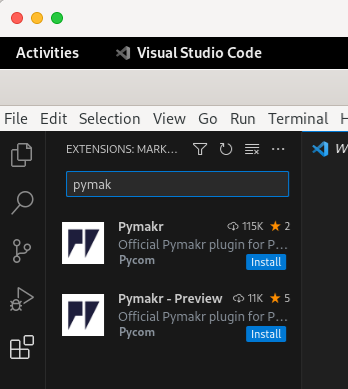

Vous découvrirez une nouvelle icône dans le menu de gauche.

**Si vous l'exécutez sur une machine virtuelle Linux, assurez-vous d'être dans le groupe dialout (et de redémarrer le système) pour accéder au port série.**

### Connexion du LoPy

Lorsque vous cliquez sur cette icône, et si un LoPy est connecté à votre ordinateur (n'oubliez pas de configurer la connexion si vous êtes sur une machine virtuelle).

![](images/run.gif)

Cliquez sur l'éclair pour vous connecter à votre appareil. Le symbole à gauche se transforme en deux prises, ce qui indique que l'appareil est connecté.

Sélectionnez le dossier contenant le répertoire pycom (de la distribution github que vous avez clonée) et dans l'interface pycom sélectionnez l'icône du dossier pour lier les deux.

Cliquez ensuite sur le carré contenant le symbole >. Cela ouvrira une fenêtre de terminal avec votre appareil. Vous pouvez taper des commandes en utilisant REPL.

Après cela, sélectionnez le fichier lorawan_devEUI.py et faites un clic droit dessus, choisissez pymaker et lancez sur le périphérique. Sélectionner l'interface USB et Ok.

Téléverser le répertoire pycom

Le répertoire pycom contient un certain nombre de module que nous utiliserons par la suite, ils doivent être présent dans la mémore flash du LoPy.

![](images/upload2.gif)

Lorsque vous faites un clic droit sur le répertoire pycom, un menu pymaker apparaît à la fin. Sélectionnez upload to device. Sélectionnez votre périphérique USB (par exemple /dev/ttyUSO0), Ok et retour chariot.

Le répertoire est téléchargé.

### Wi-Fi

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("PmvSU8AWO68", width=700, height=394)

#### Connexion à votre réseau Wi-Fi

### 

### Connexion à votre réseau Wi-Fi

Lors du téléversement des fichiers dans le Pycom, nous avons placé le fichier boot.py qui va chercher à se connecter à un réseau Wi-Fi. S’il n’y arrive pas, il transforme le Pycom en point d’accès. Au démarrage, votre Pycom a dû afficher le message suivant :

```
Failed to connect to any known network, going into AP mode
```

Le Pycom devient point d'accès Wi-Fi et va déployer son propre réseau sur lequel votre ordinateur peut se connecter.

En listant sur votre ordinateur la liste des réseaux présents autour de vous, vous en trouverez un dont le nom commence par lopy-wlan. En le sélectionnant et en donnant le mot de passe www.pycom.io, vous vous y connecterez et ensuite vous pouvez vous connecter par FTP ou telnet sur votre Pycom qui aura l’adresse 192.168.4.1. Mais ce n'est pas très intéressant car votre ordinateur va perdre sa connexion à l'internet. Pas très pratique pour suivre le MOOC.

Vous allez plutôt insérer votre Pycom dans votre réseau Wi-Fi. Pour ce faire, éditez sous Atom le fichier wifi_conf.py

```
known nets = {
’NET_SSID’: {’pwd’: ’PASSWORD’}
}
```

et remplacez NET SSID par le nom de votre réseau WIFI et PASSWORD par le mot de passe (ou clé Wi-Fi) associé. Notez que vous pouvez lister plusieurs réseaux Wi-Fi si vous le souhaitez. Resynchronisez les fichiers avec le Pycom en cliquant sur la flèche vers le haut.

Le Pycom redémarre et doit maintenant afficher un message du genre :

```
Connected to MY-WIFI with IP address:192.168.1.86
```

Vous pouvez vous connecter avec FTP ou Telnet en utilisant cette adresse IP, soit en invite de commandes ou en utilisant votre outil favori ([putty](https://www.putty.org/) par exemple).

```
$ telnet 192.168.1.86
Trying 192.168.1.86...
Connected to 192.168.1.86.
Escape character is ’ˆ]’.
MicroPython v1.8.6-760-g90b72952 on 2017-09-01; LoPy with ESP32
Login as: micro
Password: python
Login succeeded!
Type "help()" for more information.
>>>
```

### Client minimal

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("Mi3e4c2E59o", width=700, height=394)

#### Mise en place d’un client

### Mise en place d’un client

Maintenant que votre Pycom est connecté à votre réseau Wi-Fi, vous pouvez recevoir des données comme nous l’avons fait dans la section précédente.

Mais avant, notez l’adresse IP de votre ordinateur. Elle est généralement disponible en tapant la commande ifconfig dans un terminal sous Linux ou Mac, ou ipconfig sous Windows.

```
> ifconfig
eth1 Link encap:Ethernet HWaddr 10:65:30:b0:54:bf
inet addr:192.168.1.47 Bcast:192.168.1.255 Mask:255.255.255.0
inet6 addr: fe80::d8ac:86e7:8bdb:e333/64 Scope:Unknown
UP BROADCAST RUNNING MULTICAST MTU:1500 Metric:1
RX packets:0 errors:0 dropped:0 overruns:0 frame:0
TX packets:0 errors:0 dropped:0 overruns:0 carrier:0
collisions:0
RX bytes:0 (0.0 B) TX bytes:0 (0.0 B)
lo Link encap:Local Loopback
inet addr:127.0.0.1 Mask:255.0.0.0
inet6 addr: ::1/128 Scope:Unknown
UP LOOPBACK RUNNING MTU:1500 Metric:1
RX packets:0 errors:0 dropped:0 overruns:0 frame:0
TX packets:0 errors:0 dropped:0 overruns:0 carrier:0
collisions:0
RX bytes:0 (0.0 B) TX bytes:0 (0.0 B)
```

```
Lancez sur votre ordinateur le programme minimal_server.py vu dans le TP "Envoi de données structurées".
```

```
> python3 minimal_server.py
```

### 

```
Sur Atom, sélectionnez le programme sending_client.py du dossier pycom.
```

```python
import socket
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
s.sendto("message", ("192.168.1.47", 33033))
```

Ce programme ouvre une socket en mode datagramme UDP puis envoie la séquence *message* au serveur. L’adresse IP de la ligne 4 doit être celle de votre ordinateur que vous avez précédemment notée.

Lancez le programme sur le Pycom et cliquant sur le bouton en forme de triangle (*Run selected file*).

Sur votre ordinateur, le programme minimal_server.py affiche :

```
> python3 minimal_server.py
b’message’ => b’6d657373616765’
```

### 

### **Bravo ! Vous avez connecté votre Pycom à votre ordinateur et envoyé vos premières données !**

Il ne reste plus qu’à émettre de vraies données issues d'un capteur.

### Capteur BME280

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("I3zc3-qoq2s", width=700, height=394)

#### Capteur BME280

# Capteur BME280

Vous allez à présent prendre de vraies mesures de température, d'humidité et de pression à partir d’un capteur que vous allez connecter sur le Pycom.

Dans un premier temps, vous vous contenterez de les prendre sur le Pycom et vous verrez plus loin comment les envoyer sur le serveur.

Pour prendre ces mesures, vous allez vous appuyer sur un composant, **le BME280**, qui mesure la température, l’humidité et la pression atmosphérique. On communique avec le composant en utilisant un bus I2C. Il se compose de deux fils : un qui va véhiculer un signal d'horloge (SCL)  et un autre qui va transporter les données (SDA). On ajoute un fil pour alimenter le composant en 3.3v  (Vin)  et la masse (GND).

![](images/BME280.png)

Pour ce faire, connectez :

* la masse GND du Pycom sur la broche GND du composant avec un fil noir,
* l’alimentation en 3.3V du Pycom (3V3) sur VIN du composant avec un fil rouge (ce port s’appelle également DCC sur certaines cartes),
* Le signal d’horloge du port G18/P10 du Pycom (ou G17 sur les versions LoPy 1) sur le port SCL du composant avec un fil jaune (ce port s’appelle également CLC sur certaines cartes),
* Le fil de données du port G16/P9 du Pycom sur le port SDA du composant avec un fil vert.

![](images/LoPy4.png)

```
Depuis Atom, sélectionnez le programme BME280.py et lancez son exécution sur le Pycom en cliquant sur le triangle dans la fenêtre Pymakr.
```

Si le BME280 est connecté correctement sur les connecteurs du Pycom, vous devez obtenir le résultat suivant :

```
>>> Running BME280.py
>>>
>>>
[118]
temp 550576 27.98 - hum 26626 48.784 \% - pres 389338 pres 1004.494 hPa [delta -389338 ]
temp 551952 28.42 - hum 26587 48.557 \% - pres 389712 pres 1004.527 hPa [delta -374 ]
temp 551792 28.37 - hum 26577 48.491 \% - pres 389664 pres 1004.621 hPa [delta 48 ]
temp 551712 28.34 - hum 26594 48.596 \% - pres 389648 pres 1004.654 hPa [delta 16 ]
temp 551632 28.32 - hum 26587 48.546 \% - pres 389616 pres 1004.713 hPa [delta 32 ]
```

Vous pouvez soit toucher le capteur, soit souffler dessus pour faire augmenter la température ou la pression.

Le programme BME280.py peut fonctionner comme un module mais la dernière partie montre comment exploiter les résultats. Nous allons la détailler.

```python
if __name__ == "__main__":
from machine import I2C
import time
i2c = I2C(0, I2C.MASTER, baudrate=400000)
print (i2c.scan())
bme = BME280(i2c=i2c)
ob = 0
while True:
ar = bme.read_raw_temp()
a = bme.read_temperature()
br = bme.read_raw_pressure()
b = bme.read_pressure()
cr = bme.read_raw_humidity()
c = bme.read_humidity()
print ("temp", ar, a,
" - hum", cr, c,
"% - pres", br,
"pres", b,
"hPa [delta", ob - br, "]" )
ob =br
time.sleep(5)
```

Le programme principal commence par importer le module gérant le bus I2C. Il est invoqué à la ligne 286. Le Pycom va gérer la communication avec le BME280, donc l’adresse est 0 et son statut est MASTER. La vitesse de communication est ensuite spécifiée.

La ligne suivante scanne le bus pour trouver des composants. Si tout va bien, il devrait en trouver un à l’adresse 118 qui correspond à l’adresse par défaut du BME280. Sinon, revoyez votre câblage.

Le module BME280 est initialisé en lui passant en paramètre la référence du bus I2C précédemment défini.

Le programme va ensuite afficher les valeurs captées par le composant. Il existe deux types de valeurs : brutes *(raw)* et calibrées. Les premières réagissent plus rapidement aux changements cependant sont beaucoup plus bruitées que les secondes qui subissent un traitement mathématique.

Ainsi, les première et deuxième colonnes donnent les températures brute et calibrée. On y accède par les méthodes read_ raw_temp et read_temperature. Il en va de même pour les deux autres grandeurs, humidité et pression.

Le programme affiche également l’écart de pression brute entre deux mesures. Cela permet de mettre plus facilement en évidence le fait que l’on souffle sur le capteur.

### Thermomètre Wi-Fi

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("Ie-hGkkhsMQ", width=700, height=394)

#### Thermomètre Wi-Fi

# **Thermomètre Wi-Fi**

Vous avez maintenant tous les outils pour récupérer la température de votre logement, la transmettre à votre ordinateur via le Wi-Fi, et la transmettre à Beebotte pour l'afficher. Il y a très peu de changement par rapport à la version complètement sur ordinateur. Le programme de transformation de la structure CBOR de représentation des séries temporelles en JSON compréhensible par Beebottte reste le même. Il faudra juste modifier le nom du capteur d'humidité à température.

Le programme que vous avez construit lors du TP précédent utilisait le module virtual_sensor pour produire des séries temporelles aléatoires symbolisant le comportement d'un capteur. Maintenant que nous avons un BME280, nous allons pouvoir traiter de vraies valeurs.

Le programme wifi_temperature.py montre cette adaptation.

```python
import BME280
import time
import socket
import kpn_senml.cbor_encoder as cbor
from machine import I2C
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
NB_ELEMENT = 30
t_history = []
i2c = I2C(0, I2C.MASTER, baudrate=400000)
print (i2c.scan())
bme = BME280.BME280(i2c=i2c)
while True:
t = int(bme.read_temperature()\*100)
# No more room to store value, send it.
if len(t_history) == 0:
t_history = [t]
elif len(t_history) >= NB_ELEMENT:
print ("send")
s.sendto (cbor.dumps(t_history), ("192.168.1.47", 33033))
t_history = [t]
else:
t_history.append(t-prev)
prev = t
print (len(t_history), len(cbor.dumps(t_history)), t_history)
time.sleep(10)
```

Au niveau des importations de modules, BME280 et I2C remplacent virtual_sensor, et le module CBOR est celui de kpn_senml. Mais son comportement reste le même, en particulier la fonction *dumps* qui convertit une structure Python et CBOR. Il vous reste à adapter la ligne 26 pour mettre l’adresse IP de votre ordinateur.

Côté ordinateur, vous devez relancer le programme display_server.py, mais en modifiant le nom du capteur de "humidity" à "temperature".

Sur votre compte Beebotte, au bout de 300 secondes, vous devez voir des données associées au capteur "temperature".

**Et voilà ! Le programme sur votre ordinateur n’est pas modifié et vous pouvez suivre l’évolution de la température sur les widgets de beebotte.**

Dernière étape : se libérer du Wi-Fi énergivore et courte portée en utilisant un réseau LPWAN.

## TP2.3 - Aller encore plus loin avec un réseau LPWAN

### Les réseaux LPWAN

#### Les réseaux LPWAN

Pour aller encore plus loin, vous pouvez vous connecter à différents réseaux LPWAN.

![](images/LPWAN.png)

* Sigfox est une bonne solution car ce réseau a une bonne couverture territoriale et, avec votre Pycom, vous avez un accès gratuit au réseau pendant 1 an. C'est donc un bon moyen de tester le fonctionnement d'un LPWAN.
* Les réseaux LoRaWAN offrent plus de possibilités pour les tailles de messages et le nombre de messages vers le Pycom. Avant que nous ayons bien optimisé le trafic, ils seront plus tolérants aux expériences que nous allons mener. Vous pouvez trouver 3 types de réseaux LoRaWAN :

+ *The Things Network* est un réseau communautaire. Avec un peu de chance, il a une antenne près de chez vous qui pourra capter votre trafic, mais ce n'est pas garanti ;
+ vous pouvez également créer également votre propre réseau LoRaWAN privé avec :

- *Chirpstack*, mais qui demande un investissement d'environ 200€ pour avoir votre antenne ;
- si vous êtes sur un campus universitaire (par exemple de l'IMT), vous pouvez éventuellement utiliser le réseau d'Acklio. Nous verrons plus loin comment.

### Sigfox

#### Sigfox

Marre de la portée limitée du Wi-Fi et de sa consommation excessive pour en faire un thermomètre d’extérieur ?

Nous allons utiliser un réseau dédié aux capteurs : le réseau **Sigfox**.

Si vous avez acquis un LoPy 4 récemment, bonne nouvelle ! vous avez gratuitement accès au réseau Sigfox durant 1 an. Nous allons en profiter.

![](images/Sigfox.jpg)

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("mLZoeHE5Gaw", width=700, height=394)

#### Récupération des identifiants

### Récupération des identifiants

Dans un premier temps, vous devez enregistrez votre capteur sur le site de Sigfox. Il vous faut deux éléments : son identifiant et son mot de passe appelé PAC (*Porting Authorization Code*). Ce dernier doit rester secret car il permet à toute personne qui le possède d’enregistrer un objet ou d’en changer le propriétaire.

Le programme sigfox_id.py permet d’afficher ces deux valeurs et d’envoyer un message sur le réseau Sigfox. Avant de l’exécuter, vérifiez que vous avez branché une antenne sur le connecteur de droite, celui opposé au bouton Reset sur le Pycom, coté LED.

```python
from network import Sigfox
import binascii
import socket
# initalise Sigfox for RCZ1 (You may need a different RCZ Region)
# RCZ1: Europe, Oman, South Africa
# RCZ2: USA, Mexico, Brazil
# RCZ3: Japan
# RCZ4: Australia, New Zealand, Singapore, Taiwan, Hong Kong, Columbia, Argentina
sigfox = Sigfox(mode=Sigfox.SIGFOX, rcz=Sigfox.RCZ1)
# print Sigfox Device ID
print("Sigfox ID:", binascii.hexlify(sigfox.id()))
# print Sigfox PAC number
print("PAC Number:", binascii.hexlify(sigfox.pac()))
s = socket.socket(socket.AF_SIGFOX, socket.SOCK_RAW)
s.send("Hi! Sigfox")
```

Ce programme importe l’objet Sigfox du module network (ligne 1) et crée une instance sigfox (ligne 10). Il est important de bien spécifier la bonne région d’utilisation car les bandes de fréquences peuvent différer d'un continent à un autre. En plus d’émettre dans l’illégalité, le réseau Sigfox ne recevra pas les messages.

Les lignes 13 et 16 affichent les identifiants Sigfox de votre Pycom. Notez-les, ils nous serviront pour enregistrer l’objet sur le réseau de Sigfox.

La ligne 18 crée une socket, à l’instar de ce qui avait été fait avec UDP au TP précédent. On peut donc utiliser les mêmes primitives en Sigfox qu’en UDP. La ligne 19 permet d’envoyer un message que vous pouvez personnaliser dans la limite de 12 caractères ; taille maximale des trames Sigfox.

#### Enregistrement de l'objet

### Enregistrement de l'objet

Maintenant que vous avez les précieux identifiants Sigfox, connectez-vous avec un navigateur sur le site [https://backend.sigfox.com/activate]( https://backend.sigfox.com/activate). Le processus est très simple. Il suffit de remplir les champs des différents formulaires :

* indiquez votre pays ;
* remplissez le formulaire avec l'identifiant de l'objet et le PAC que vous avez obtenus avec le programme sigfox_id.py ;
* indiquez à des fins de statistique ce qui vous amène ici ;
* créez votre compte Sigfox ;

ce qui va conduire à enregistrer l’objet et à vous créer un compte sur le *backend* de Sigfox.

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("wBccbspakV0", width=700, height=394)

#### Visualisation des données

### Visualisation des données émises par le Pycom

Rendez-vous sur le *backend* de Sigfox (<https://backend.sigfox.com/>) et identifiez-vous avec le compte que vous venez de créer.

![](images/sigfox_accueil.png)

Les onglets en haut de la page vont vous permettre de naviguer dans différents types d’information. Dans ce MOOC, nous n'utiliserons que l'onglet DEVICE.

L’onglet DEVICE vous donne accès aux objets enregistrés vous appartenant :

![](images/sigfox_device.png)

On y retrouve un nom créé par Sigfox en fonction du type d’objet, le propriétaire et l’ID que vous avez donnés lors de l’enregistrement, et la date du dernier message reçu par Sigfox pour cet objet. En cliquant sur le nom de l’objet, vous pouvez le configurer. En cliquant sur le nom du groupe, vous aurez aussi accès à des paramètres d’administration des objets. Finalement, en cliquant sur l’ID de l’objet vous aurez des informations concernant les messages reçus puis, en cliquant dans MESSAGES dans le menu de gauche, vous aurez la liste des messages reçus par Sigfox.

![](images/sigfox_message.png)

L'idéal serait d’avoir directement accès à ces données pour pouvoir les manipuler dans un programme. Pour ce faire, nous pouvons utiliser l’API REST développée par Sigfox.

Dans l’onglet DEVICE*,* cliquez sur le nom de votre groupe puis, dans le menu de gauche, sur API ACCESS. Enfin, en haut à droite, sur le tout petit bouton *New*.

![](images/sigfox_api_access.png)

Donnez un nom à cet accès et choisissez, dans le menu Profiles, *DEVICE MESSAGE [R]* pour avoir le droit de lire les messages. Puis évidemment, sur Ok.

Vous voyez apparaitre une nouvelle page avec deux champs en hexadécimal : login et password, que vous devez noter ou apprendre par cœur pour la suite.

#### Traitement des données

### Traitement des données sur votre ordinateur

Nous avons tous les éléments pour émettre un relevé de température en utilisant le réseau Sigfox. Nous allons reprendre le programme pour Pycom dédié au Wi-Fi  et ajouter la contrainte des 12 octets maximum pour la structure CBOR.

Nous avons les clés d’accès à l’API, il suffit maintenant d’écrire un petit script Python.

Pour des raisons de sécurité, nous vous invitons à prendre l'habitude de mettre les informations sensibles dans un fichier séparé.

Le programme device_message.py permet de lister les messages reçus par Sigfox pour un objet particulier sur votre ordinateur.

```python
import requests
import os
from requests.auth import HTTPBasicAuth
import pprint
import json
from config_sigfox import API_USER, API_PASSWORD, DEVICEID
import binascii
url = 'https://backend.sigfox.com/api/v2/devices/'+DEVICEID+'/messages'
print(url)
r = requests.get(url, auth=HTTPBasicAuth(API_USER, API_PASSWORD))
print (r.status_code)
if r.status_code != 200:
exit
resp = json.loads(r.text)
pprint.pprint(resp)
for v in resp["data"]:
print ("{:10d}: {:2d} {:25} {:20} received {}".format(
v["time"], v["seqNumber"],
v["data"], "["+str(binascii.unhexlify(v["data"]))+"]",
len(v["rinfos"])
))
```

Ligne 9, l’URL comportant l’ID de l'objet est construite et la demande est faite ligne 13 avec la méthode d’authentification basée sur le mot de passe. Si le code retourné est 200, tout s’est bien passé et r.text contient la réponse. Cette réponse est une chaîne de caractères qui est désérialisée ligne 19 pour en faire une représentation JSON qui va être exploitée dans la suite. Ligne 20, la réponse est affichée et ensuite certains éléments sont donnés. La clé :

* "time" donne l’heure de réception codée suivant le format Epoch, évoqué lors de la communication avec Beebotte précédemment ;
* "seqNumber" contient le numéro de la trame et est remis a 0 quand l’objet est reflashé. Il permet de détecter des pertes de données si les numéros ne sont pas contigus ;
* "data" contient les données codées dans une chaîne hexadécimale. Le programme utilise la fonction unhexifily pour la reconvertir en séquence d’octets qui peuvent être affichés s’il s’agit de caractères ACSII ;
* "rinfos" donne les informations sur les différentes passerelles radio de l’opérateur qui ont reçu le message.

#### Affichage de la température

### Affichage de la température

Le programme wifi_temperature.py se décline facilement pour Sigfox. La plus grande difficulté est de ne pas dépasser la limite des 12 octets pour la structure CBOR. Le programme suivant sigfox_temperature.py adapte la socket et la taille des données.

```python
import BME280
import time
import socket
import kpn_senml.cbor_encoder as cbor
from machine import I2C
from network import Sigfox
import binascii
import socket
# initalise Sigfox for RCZ1 (You may need a different RCZ Region)
sigfox = Sigfox(mode=Sigfox.SIGFOX, rcz=Sigfox.RCZ1)
s = socket.socket(socket.AF_SIGFOX, socket.SOCK_RAW)
FRAME_MAX = 12
t_history = []
i2c = I2C(0, I2C.MASTER, baudrate=400000)
print (i2c.scan())
bme = BME280.BME280(i2c=i2c)
while True:
t = int(bme.read_temperature()\*100)
# No more room to store value, send it.
if len(t_history) == 0:
t_history = [t]
else:
t_history.append(t-prev)
print (t_history, len(cbor.dumps(t_history)))
if len(cbor.dumps(t_history)) > FRAME_MAX:
# oops too big for Sigfox
t_history = t_history[:-1] # remove last item
s.send (cbor.dumps(t_history))
t_history = [t]
prev = t
time.sleep(10)
```

Nous allons voir comment récupérer les données du côté de l'ordinateur en définissant deux méthodes. L'une qui ne demande pas de réglage sur votre réseau, mais qui est très spécifique à Sigfox ; l'autre qui va vous demander de configurer votre NAT pour recevoir des requêtes venant de l'opérateur vers votre machine.

#### Méthode plus complexe

### Méthode plus complexe à programmer mais sans configuration de votre réseau

Côté ordinateur, la stratégie la plus simple à mettre en œuvre consiste à étendre le programme device_message.py vu précédemment et d'interroger périodiquement le *backend* de Sigfox pour voir si de nouvelles données sont arrivées. Cela donne le programme display_sigfox.py suivant :

```python
import requests
import os
from requests.auth import HTTPBasicAuth
import pprint
import json
from config_sigfox import API_USER, API_PASSWORD, DEVICEID
import binascii
import time
import datetime
import cbor2 as cbor
import beebotte
import config_bbt
bbt = beebotte.BBT(config_bbt.API_KEY, config_bbt.SECRET_KEY)
def to_bbt(channel, res_name, cbor_msg, factor=1, period=10, epoch=None):
global bbt
prev_value = 0
data_list = []
if epoch:
back_time = epoch
else:
back_time = time.mktime(datetime.datetime.now().timetuple())\*1000
back_time -= len(cbor_msg)\*period
for e in cbor_msg:
prev_value += e
back_time += period
data_list.append({"resource": res_name,
"data" : prev_value\*factor,
"ts": back_time} )
pprint.pprint (data_list)
bbt.writeBulk(channel, data_list)
url = 'https://backend.sigfox.com/api/v2/devices/'+DEVICEID+'/messages'
last_epoch = 0
# get the last message to find the starting epoch
parameters = {'limit': 1 }
r = requests.get(url, auth=HTTPBasicAuth(API_USER, API_PASSWORD), params=parameters)
print (r.status_code)
if r.status_code != 200:
exit
j = json.loads(r.text)
last_epoch = j["data"][0]["time"]
# delay next request to avoid 429 status error
time.sleep(10)
# look periodically if new data arrived.
while True:
if last_epoch > 0:
parameters = {"since": last_epoch+1}
else:
parameters = None
print (parameters)
r = requests.get(url, auth=HTTPBasicAuth(API_USER, API_PASSWORD), params=parameters)
print (r.status_code)
if r.status_code != 200:
break
resp = json.loads(r.text)
for v in resp["data"]:
if last_epoch < v["time"]:
last_epoch = v["time"]
print ("{:10d}: {:2d} {:25} {:20} received {}".format(
v["time"], v["seqNumber"],
v["data"], "["+str(binascii.unhexlify(v["data"]))+"]",
len(v["rinfos"])
))
measure = cbor.loads(binascii.unhexlify(v["data"]))
sending_time = v["time"]
print (sending_time, measure)
to_bbt("capteurs", "temperature", measure, factor=0.01, period=10, epoch=sending_time)
time.sleep(60)
```

Pour ce faire, nous allons ajouter des paramètres à la requête. Dans un premier temps, le paramètre limit mis à 1 (lignes 46 et 47) nous permet d’avoir le dernier enregistrement et d'obtenir son heure de réception. Le programme va considérer ces messages toujours stockés dans le *backend* de Sigfox comme anciens.

Puis périodiquement, le programme va demander s'il y a des nouveaux messages par rapport à cette date en utilisant le paramètre since (lignes 66 et 73) avec la date que nous avons obtenue lors de la première requête.

Quand un message est trouvé, il est transformé au format de Beebotte et envoyé grâce à la fonction to_bbt décrite à la session précédente. La seule différence avec la version avec capteurs virtuels ou Wi-Fi est que nous utilisons le temps de réception donné par Sigfox plutôt que le temps de réception par notre programme, vu que l’interrogation périodique du *backend* rend ce temps caduc.

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("3y0U2E6x4kE", width=700, height=394)

#### Autre méthode

### Méthode demandant plus de configuration, surtout derrière un NAT, mais qui va ressembler à ce que l'on avait avec le Wi-Fi

Nous avons dû modifier la logique du programme display_sigfox.py. Au lieu d’attendre des données comme le faisait display_server.py, il va chercher activement les données sur le *backend*. Cela est imposé par les limitations de l’adressage IPv4 privé que vous avez certainement sur votre réseau local. En effet, il n’est pas possible d’être joint par l’extérieur, les connexions ne se font qu’à l’initiative de l’équipement qui a une adresse privée. Pour revenir au cas précédent où le *backend* pourrait pousser des données, on peut soit faire tourner le programme sur une machine virtuelle dans le Cloud (ex : VPS d’OVH) ou configurer le NAT de votre boîtier Internet pour autoriser des connexions entrantes sur un port particulier. C’est cette dernière option que nous allons détailler. Bien entendu, les caractéristiques des NAT changent d’un opérateur à un autre ; nous ne pourrons pas détailler sa configuration.

Dans un premier temps, rendez-vous sur [https://backend.sigfox.com/device/list]( https://backend.sigfox.com/device/list), cliquez sur le nom de l’objet puis, dans le menu de gauche, sur *Callback*, puis *New*.

Une page apparaît avec la possibilité de connecter l’objet à différentes plateformes. Nous choisissons *Custom callback* car nous voulons garder notre indépendance.

La figure suivante montre le formulaire.

![](images/sigfox_callback.png)

Dans un premier temps, il faut déterminer l’adresse IP publique derrière votre NAT. Un site comme <https://wtfismyip.com/> peut aider. L’URI de votre serveur sera quelque chose comme indiqué sur la figure pour l'*Url Pattern*.

Attention, certains opérateurs changent régulièrement l’adresse IP alloué au NAT. Il est donc préférable d’utiliser un DNS dynamique si vous voulez l’utiliser à long terme.

Changez la méthode de GET par un POST, c’est quand même plus propre. Le GET étant un moyen de récupérer de l’information pas d’en transmettre si on veut rester compatible avec REST.

Ce n’est pas fini. Il faut maintenant formater le contenu. Dans *Content type*, remplacez la valeur par application/json car c’est ce que l’on sait faire de mieux. Dans la fenêtre en dessous, nous allons définir notre format JSON avec deux clés : deviceId et data, suivies de deux variables entre accolades que Sigfox remplacera par les vraies valeurs.

Finalement, cliquez sur *Ok*.

Il vous reste à configurer le NAT de votre routeur d’accès pour que les paquets à destination du port 9999 (valeur choisie dans l’URI) TCP soient envoyés à l’adresse privée de votre ordinateur. À titre d'exemple, voici quelques tutoriels qui pourraient vous aider :

* Pour Orange : [Tutoriel : passer en NAT ouvert sur sa Livebox Orange - Chroniques d'un Geek (geek-chronicles.com)](https://geek-chronicles.com/514-tutoriel-passer-en-nat-ouvert-sur-sa-livebox-orange/)
* Pour Free : [ouverture ports xbox one freebox v6/opening ports xbox one - YouTube](https://www.youtube.com/watch?v=scvV2LK5YcE)
* Pour Bouygues Télécom : [Assistance paramétrage box adsl plug&play | Bouygues Telecom Entreprises (bouyguestelecom-entreprises.fr)](https://www.bouyguestelecom-entreprises.fr/assistance/internet-reseaux/box-adsl-plug-and-play/parametrage-box-adsl)
* Pour SFR: [Routage NAT et redirection de port sur box SFR | Infraworld](https://www.infraworld.fr/2014/09/30/routage-nat-et-redirection-de-port-sur-box-sfr/)

Si vous avez des difficultés, on peut en parler dans le forum.

Si vous ne pouvez pas le faire, vous pouvez casser votre tirelire pour vous acheter un VPS avec une adresse IP publique pour 3 € par mois. Dans ce cas, il faudra installer Python3 et les modules nécessaires (Beebotte, cbor2...)

Nous allons prendre les données contenues dans la requête POST venant du *backend* de Sigfox et la transférer sur le lien *loopback* de votre ordinateur vers le port UDP 33033. Comme ça, nous pourrons réutiliser le programme display_server.py que nous avons écrit au bon vieux temps où nous émulions des capteurs, voire pour les plus téméraires, utilisions le Wi-Fi. De cette manière, nous banalisons le programme qui pourra traiter ces trois sources d’information (terminal en émulation, Pycom avec Wi-Fi, Pycom avec Sigfox et bien plus encore). Le programme generic_relay.py le fait pour Sigfox et différents serveurs LoRaWAN. Nous ne dévoilerons ici que les lignes liées au traitement de Sigfox.

```python
@app.route('/sigfox', methods=['POST'])
def get_from_sigfox():
fromGW = request.get_json(force=True)
print ("SIGFOX POST RECEIVED")
pprint.pprint(fromGW)
downlink = None
if "data" in fromGW:
payload = binascii.unhexlify(fromGW["data"])
downlink = forward_data(payload)
resp = Response(status=200)
print (resp)
return resp
```

Le programme utilise le module Flask que nous avions vu au début du cours dans le TP HTTP. Nous définissons le chemin /sigfox qui correspond à l'URI définie sur la *backend* de Sigfox. Bien entendu, nous n'acceptons que les POST.

request.get_json(force=True) désérialise le contenu du POST. Le paramètre force est là au cas où vous auriez oublié de mettre sur le *backend* le format du contenu à application/json.

Si le POST contient des données (clé JSON data), alors elles sont envoyées sur le lien *loopback* via la fonction forward_data (ligne 62) .

Et après ces efforts de configuration, vous pouvez enfin afficher les températures sur Beebotte.

Dans un premier terminal, generic_relay.py affiche ces logs :

```
%python3 sigfox_relay.py
\* Serving Flask app "sigfox_relay" (lazy loading)
\* Environment: production
WARNING: This is a development server. Do not use it in a production deploymen
Use a production WSGI server instead.
\* Debug mode: on
\* Running on http://0.0.0.0:9999/ (Press CTRL+C to quit)
\* Restarting with stat
\* Debugger is active!
\* Debugger PIN: 182-156-691
HTTP POST RECEIVED
’data’: ’871907aa1901f92323010303’, ’deviceId’: ’4D55AC’
<Response 0 bytes [200 OK]>
185.110.97.83 - - [14/Aug/2020 10:59:16] "POST /sigfox HTTP/1.1" 200 HTTP POST RECEIVED
’data’: ’891909a20202000100000000’, ’deviceId’: ’4D55AC’
<Response 0 bytes [200 OK]>
185.110.97.83 - - [14/Aug/2020 11:00:46] "POST /sigfox HTTP/1.1" 200 HTTP POST RECEIVED
’data’: ’891909a80220022021012000’, ’deviceId’: ’4D55AC’
<Response 0 bytes [200 OK]>
...
```

Dans un second terminal, display_server.py traite les données :

```
%python3.7 display_server.py
[’data’: 19.62, ’resource’: ’humidity’, ’ts’: 1597395496000.0,
’data’: 24.67, ’resource’: ’humidity’, ’ts’: 1597395506000.0,
’data’: 24.63, ’resource’: ’humidity’, ’ts’: 1597395516000.0,
’data’: 24.59, ’resource’: ’humidity’, ’ts’: 1597395526000.0,
’data’: 24.6, ’resource’: ’humidity’, ’ts’: 1597395536000.0,
’data’: 24.63, ’resource’: ’humidity’, ’ts’: 1597395546000.0,
’data’: 24.66, ’resource’: ’humidity’, ’ts’: 1597395556000.0]
[’data’: 24.66, ’resource’: ’humidity’, ’ts’: 1597395566000.0,
’data’: 24.68, ’resource’: ’humidity’, ’ts’: 1597395576000.0,
’data’: 24.7, ’resource’: ’humidity’, ’ts’: 1597395586000.0,
...
```

#### Conclusion

### Conclusion

On a un prototype de capteur qui fonctionne sur Sigfox. À vous de l’améliorer. En particulier, il faut augmenter l’intervalle entre deux mesures qui a été fixé à 10 secondes pour ne pas avoir à faire des tests trop longs.

Comme la taille d’un message est de 12 octets, CBOR va prendre 1 octet pour coder le tableau et la valeur de référence est codée sur 3 octets. Si les deltas sont petits, ils tiendront sur un octet. Il reste de la place pour 8 deltas. Donc, la période d’émission est de 90 secondes si les intervalles entre deux mesures restent à 10 secondes.

Comme Sigfox n'autorise que 140 messages par jours, la durée de mesure ne sera que de 210 minutes par jours, soit 3 heures et demie. Il est donc préférable de prendre des intervalles plus grands. Vous pouvez calibrer votre Pycom et votre programme de réception pour pouvoir suivre la température sur une journée.

Le programme display_server.py permet de récolter des informations de plusieurs sources : un programme en local qui émule les mesures, du réseau Wi-Fi et par l'intermédiaire de generic_relay.py provenant d'un réseau LPWAN. Nous avons notre convention de représentation de l'information basée sur CBOR pour définir une série temporelle. En revanche, nous avions été obligés de modifier le programme display_server.py quand nous étions passé d'une série temporelle représentant l'évolution de l'humidité à une autre traitant de la température.

Pour revenir au paradigme de REST, nous avons, avec CBOR, défini le contenu de la ressource mais nous ne l'avons pas nommée. C'est ce que nous allons voir dans la prochaine session avec le protocole CoAP.

### LoRaWAN en général

#### LoRaWAN

### LoRaWAN

Avec Sigfox, ce n’était que du bonheur ! Nous avions un environnement unique développé par un seul acteur. L’attachement d’un objet au réseau, la récupération des données s’en trouve grandement simplifiée.

Avec LoRaWAN, l'écosystème est plus complexe. Pour rappel, LoRa est une modulation longue portée et LoRaWAN un protocole de niveau 2 qui a pour but de fédérer les acteurs (fabricants d’objets, utilisateurs d’objets, opérateur de réseaux) autour de la communication radio entre l’objet et le cœur de réseau appelé ici LNS (LoRa Network Server). Mais l’enregistrement des objets, le lien entre les applications et le LNS diffèrent d’un réseau à un autre.

![](images/LORAWAN-devices-sensors.png)

Même si vous n’avez pas l’intention de mettre en œuvre le réseau Sigfox, nous vous recommandons de lire le chapitre précédent (ou à la rigueur de le survoler) car nous y ferons référence dans la suite du texte.

LoRaWAN, comme Sigfox, opère dans la même bande de fréquences non licenciées. Il existe plusieurs opérateurs de réseaux LoRaWAN :

* *The Things Network* ou TTN propose une approche communautaire. Chaque personne peut mettre à disposition des passerelles radio pour la communauté et inscrire des objets. TTN gère le cœur de réseau. Si cette approche est sympathique, la couverture va être très parcellaire et va dépendre de la densité de *geeks* dans une région. De plus, la couverture du réseau va dépendre de la position des antennes qui doivent être placées sur un point haut. Avoir une antenne sur son balcon n’implique pas une grande couverture de la zone. Si vous avez de la chance, vous pourrez peut-être bénéficier d’un accès via TTN. Nous verrons comment s’y connecter.
* des opérateurs nationaux comme, en France, Orange ou Bouygues Télécom. Mais il faut généralement bourse délier pour connecter les objets et pour limiter l’usage du *downlink* ; l’envoi des messages vers les capteurs est facturé en supplément.
* les réseaux privés. Il est possible de faire tourner son propre LNS. Cela implique d’acheter des composants pour faire une passerelle radio.

#### Insertion d’un objet

### Insertion d’un objet

Chaque objet va avoir un identifiant unique codé sur 64 bits appelé *devEUI.* Cette information est nécessaire pour faire entrer un équipement sur le réseau. Le programme lorawan_devEUI.py donne accès à cette valeur qui est unique pour chaque Pycom.

```python
from network import LoRa
import pycom
import binascii
#
lora = LoRa(mode=LoRa.LORAWAN)
mac = lora.mac()
#
print ('devEUI: ', binascii.hexlify(mac))
#
```

L’objet Python LoRa est importé du module network et une instance est créée ligne 5. La variable mac va stocker l’adresse MAC retournée par l’objet lora et l'afficher en hexadécimal, comme le montre l’exemple suivant :

```
>>> Running lorawan_devEUI.py
>>>
>>>
devEUI: b'70b3d5499069ffd6'
>
```

On a le *devEUI.* Il manque encore 3 informations :

* *appEUI :* c’est un identifiant sur 64 bits comme le *devEUI* qui va servir à identifier l’application. On peut le mettre à 0 mais TTN imposera une valeur à l’inscription de l’objet ;
* *AppKey :* c’est une valeur sur 128 bits qui n’est connue que de l’objet et du LNS. Elle permet de dériver les clés de chiffrement utilisées par la suite ;
* le connecteur : il s’agit d’indiquer au LNS comment envoyer les données vers une application. Il peut s’agir de POST HTTP comme nous avons vu avec la configuration du *backend* avec Sigfox.

Bien entendu, ça serait trop simple si tous les systèmes fonctionnaient de la même façon. Nous allons donc voir comment faire avec votre réseau LoRaWAN favori.

### TTN

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("G69mjg80-mA", width=700, height=394)

#### Ajout d'un objet

# The Things Network

*The Things Network,* ou TTN pour les intimes, est un réseau communautaire qui permet à tout un chacun de connecter soit une passerelle radio pour le bénéfice de la communauté, soit un objet. TTN se charge de faire tourner un LNS et de renvoyer les informations collectées à son propriétaire.

### Création d'un compte

La première étape consiste à se créer un compte, gratuit comme il se doit, sur le site de TTN : <https://www.thethingsnetwork.org/>.

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/ttn_create.gif)

### Création d'une application

Une fois le formulaire de création de compte rempli et validé, vous disposez d’un accès au réseau TTN. C’est ce que l’on voit sur la figure suivante.

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/ttn_log2.gif)

Votre identifiant apparait en haut à droite.

* **Cliquez sur votre nom,**
* **sélectionnez Console,**
* **puis votre zone géographique** (cela n'a rien à voir avec le plan de fréquence. Il est préférable de choisir le serveur le plus proche pour optimiser les communications).

On peut soit connecter une passerelle radio (*Go To Gateways*), soit définir une application et y associer des objets. Par la suite, nous explorerons cette option si vous voulez installer votre propre passerelle radio.

Nous allons nous intéresser à ce second cas**en cliquant sur *Go To Applications***. TTN vous invite à créer notre première application ; **cliquez sur le lien +*Add Application***.

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/ttn_app.gif)

Il faut **remplir le formulaire en indiquant** :

* **l'identifiant de l'application.** Il s'agit d'un nom uniquement composé de lettres et de chiffres ainsi que du tiret. Il doit être unique pour TTN. Donc, faites preuve d'imagination. Ce nom se retrouvera dans les URI permettant de piloter l'application ;
* **le nom de l'application** qui apparaîtra dans les menus. Il n'y a pas de contraintes ; il vaut mieux choisir quelque chose d'explicite ;
* une description de l'application si nécessaire.

**Cliquez sur *Create Application*.**

### **Ajout d'un objet**

Nous devons enregistrer un ou plusieurs objets dans notre application.

* **Cliquez sur *0 end devices***
* **puis *+ Add end device***
* **et*try manual registration.***

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/ttn_reg_dev.gif)

* **Entrez le plan fréquence compatible avec votre région**. En Europe, vous pouvez choisir d'avoir la voie descendante en SF9 ou en SF12. Le premier est un bon compromis entre la portée et la durée d'émission ; le second est à choisir si votre objet est difficilement accessible (profondément enfoui ou loin d'une passerelle radio) ;
* **la version du protocole LoRaWAN compatible avec les LoPy  : *MAC V1.0.2 ;***
* **les paramètres de la couche physique : *PHY V1.0.2 REV A*.**
* **Vous devez récupérer le *devEUI* de votre *LoPY*** en lançant sur Atom le programme lorawan_devEUI.py.

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/atom_devEUI.gif)

* **Recopiez le *DevEUI* dans le formulaire de TTN,**
* **mettez *l'AppEUI* à 0,**
* et **générez une clé de chiffrement*AppKey***.

L'interface de TTN vous propose un identifiant pour l'objet basé sur son devEUI. Vous pouvez le garder.

* **Cliquez sur *register end device***

L'interface affiche une page récapitulative. **Copiez l'*AppKey* pour la mettre dans le programme****lorawan_send_an_receive.py**.

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/atom_join.gif)

### *Join* et envoi de données

Si tout va bien, qu'une passerelle radio est à portée de votre objet, le programme  lorawan_send_and_receive.py va se connecter au réseau après avoir affiché 3 fois Not yet joined... correspondant au 5 secondes prévues par le standard avant d'accepter l'objet.

La led passe du blanc au rouge indiquant qu'un message a été émis puis doit s'éteindre et le message timeout in receive est affiché.

Côté LNS, il est possible de voir le trafic sur la page résumant les caractéristiques de l'objet dans la fenêtre *live data*.

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/atom_send.gif)

Cette fenêtre affiche que le *join* a été accepté puis les données transmises par l'objet apparaissent.

* Cliquez sur *see all activity* pour afficher plus de contenu.
* Cliquez sur la trame de donnée. Une structure JSON est affichée. En allant sur les clés uplink_message et frm_payload, on obtient la séquence base64 correspondant aux données émises par l'objet. Dans notre exemple, la séquence SGVsbG8gTG9SYQ== correspond à la chaîne de caractères Hello LoRa

#### Connecteur

### Configurez le connecteur

Le LNS reçoit les données, parfait ! Mais il faut lui dire quoi en faire. Pour cela, nous devons créer un connecteur. TTN en possède des préconfigurés pour aller vers des services de traitement de données mais, à notre habitude, nous allons tout faire pas à pas pour comprendre la logique. Comme avec Sigfox, nous allons émettre une requête POST quand des données seront reçues par le LNS.

* **Cliquez dans le menu de droite sur *Integrations***
* **puis choisissez *Webhooks***
* **et *+ add webhook***
* **Allez en bas de la page et sélectionnez*Custom Webhook***

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/ttn_uplink.gif)

Un formulaire apparait :

* **Donnez un identifiant à votre connecteur** qui ne doit contenir que des lettres, des chiffres et un tiret.
* **Sélectionnez le format JSON.**
* **Donnez l'URI qui identifie le serveur**. Comme pour Sigfox, vous devez donner l'adresse IP publique de votre NAT ou l'adresse publique d'un serveur dans le *cloud*. Comme pour Sigfox, nous allons utiliser le port 9999, mais le chemin d'URI sera /ttn.

Nous devons préciser quels sont les événements qui vont déclencher l'émission d'un POST par le LNS. Nous allons juste **sélectionner la réception d'un *uplink message*** par le LNS.

**Validez votre connecteur en cliquant sur *Add webhook*.**

### Vérification

Nous pouvons vérifier que notre serveur (*Application Server* dans la terminologie LoRaWAN) reçoit correctement les POST de TTN. Si vous avez testé avec Sigfox, il n'y a pas de nouvelle configuration à faire. Sinon, reportez-vous à la section Sigfox pour voir comment configurer le NAT.

Sur votre serveur,

* **allez dans le répertoire plido-tp3**
* **et lancez le programme generic_relay.py**

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/cloud_receive.gif)

Quand le *LoPy* émet une donnée, le programme reçoit une structure JSON similaire à celle que nous avions vue sur le serveur TTN. La donnée émise par l'objet est identifiée par les clés uplink_message et frm_payload.

Nous pouvons jeter un coup d'œil au programme generique_relay.py pour voir comment est traitée la réception des données.

```python
@app.route('/ttn', methods=['POST']) # API V3 current
def get_from_ttn():
fromGW = request.get_json(force=True)
pprint.pprint(fromGW)
downlink = None
if "uplink_message" in fromGW:
payload = base64.b64decode(fromGW["uplink_message"]["frm_payload"])
downlink = forward_data(payload)
if downlink != None:
downlink_msg = {
"downlinks": [{
"f_port": fromGW["uplink_message"]["f_port"],
"frm_payload": base64.b64encode(downlink).decode()
}]}
downlink_url = "https://eu1.cloud.thethings.network/api/v3/as/applications/" + \
fromGW["end_device_ids"]["application_ids"]["application_id"] + \
"/devices/" + \
fromGW["end_device_ids"]["device_id"] + \
"/down/push"
headers = {
'Content-Type': 'application/json',
'Authorization' : 'Bearer ' + TTN_Downlink_Key
}
print(downlink_url)
print (downlink_msg)
print (headers)
x = requests.post(downlink_url, data = json.dumps(downlink_msg), headers=headers)
print(x)
resp = Response(status=200)
print (resp)
return resp
```

La partie réception de données est relativement triviale. Avec le module *Flask,* le chemin /ttn est associé à la fonction get_from_ttn (attention ! dans le code, il existe aussi un /TTN qui correspond à une ancienne version de l'interface).

```
fromGW = request.get_json(force=True)
pprint.pprint(fromGW)
```

récupère les données JSON envoyées par le LNS et les affiche.

Si la structure JSON contient la clé *uplink_message*, le POST a été déclenché par la réception d'une trame de données et l'on peut dans ce cas les traiter. Comme dans le cas de Sigfox, les données sont envoyée à la fonction forward_data pour les envoyer à un autre programme qui les traitera.

```
if "uplink_message" in fromGW:
payload = base64.b64decode(fromGW["uplink_message"]["frm_payload"])
downlink = forward_data(payload)
```

Comme ce programme n'est pas lancé, la variable *downlink* reste à *None* et le programme se termine en acquittant le POST.

```python
resp = Response(status=200)
print (resp)
return resp
```

#### Voie descendante

### Tester la voie descendante

Depuis l'interface Web de TTN, il est possible d'envoyer un message à l'objet :

* **Cliquez sur *End device* dans le menu de gauche.**
* **Sélectionnez votre objet**
* **puis l'onglet *Messaging* et *Downlink.***
* **Entrez votre message codé en hexadécimal.**

### 

Votre *LoPY* affichera le message après avoir émis sa prochaine trame.

### Gestion de la voie descendante

Remonter des informations provenant du capteur ne pose pas de problème de sécurité quand le LNS pousse les données vers le serveur d'application. L'URL a été configurée dans le LNS. Cependant, pour que le LNS reçoive des informations, c'est un peu plus complexe car la requête provenant du serveur d'application doit être authentifiée.

Il faut définir une clé qui sera mise dans les en-têtes des requêtes HTTP que nous enverrons au LNS. À cette clé, nous associerons le droit d'écrire des données sur l'objet.

* **Allez dans le menu de gauche sur API keys ;**
* **cliquez sur *+ Add API key*.**

Nous allons limiter les droits associés à la clé **en cliquant sur *Grant individual rights* et en ne sélectionnant que *Write downlink application traffic.***

* **Cliquez sur *Create API Key***

Une nouvelle fenêtre apparait. **Copiez la clé.**

![](https://studio.fun-mooc.fr/asset-v1:MinesTelecom+04038+session01+type@asset+block/ttn_key.gif)

**Recopiez la clé sur votre serveur dans le fichier ttn_config dans la variable TTN_Downlink_Key.**

 TTN_Downlink_Key = "NNSXS.65SJULNSXQ4IOQZ......

La clé doit commencer par NNSXS.

On peut continuer à analyser le programme *generic_relay.py* pour voir comment il traite des messages en *downlink*. Si la fonction forward_data fournit une réponse, la variable *downlink* n'est plus à *None*.

Dans ce cas, on crée le message descendant. TTN attend cette structure JSON qui est un tableau contenant les messages pouvant être envoyés à l'objet :

```
downlink_msg = {
"downlinks": [{
"f_port": fromGW["uplink_message"]["f_port"],
"frm_payload": base64.b64encode(downlink).decode()
}]}
```

On peut noter que la valeur f_port est prise du message montant et que le contenu est traduit en base64 (la fonction decode permet de convertir une chaine d'octets commençant par b'... en une chaine de caractères compatibles avec le format JSON).

L'URI, pour permettre au LNS d'envoyer le message vers l'objet, contient les identifiants de l'application et de l'objet, que l'on récupère dans le message montant :

```
downlink_url = "https://eu1.cloud.thethings.network/api/v3/as/applications/" + \
fromGW["end_device_ids"]["application_ids"]["application_id"] + \
"/devices/" + \
fromGW["end_device_ids"]["device_id"] + \
"/down/push"
```

Pour plus de détails, l[e format de cet URI est défini sur le site web de TTN](https://www.thethingsindustries.com/docs/integrations/webhooks/scheduling-downlinks/#scheduling-downlinks).

La requête HTTP doit également contenir dans son en-tête la clé permettant de valider un message descendant vers l'objet. Ceci se fait en définissant l'objet JSON suivant :

```
headers = {
'Content-Type': 'application/json',
'Authorization' : 'Bearer ' + TTN_Downlink_Key
}
où TTN_Downlink_Key provient du fichier de configuration ttn_config.py.
```

Finalement, la requête est émise grâce à la fonction post du module requests.

```
x = requests.post(downlink_url, data = json.dumps(downlink_msg), headers=headers)
```

**Vous pouvez tester simplement la réception des messages descendant vers votre *LoPy* en ajoutant une ligne dans le programme generic_relay.py.**

```
payload = base64.b64decode(fromGW["uplink_message"]["frm_payload"])
downlink = forward_data(payload)
downlink = b'Hello LoPy!'
N'oubliez pas de retirer cette ligne pour la suite.
```

#### Ajouter une passerelle



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("2VZRweC4fbo", width=700, height=394)

#### Installation de la Gateway

### Installation d'un Passerelle Radio

Vous voulez installer une passerelle radio LoRaWAN chez vous pour bénéficier d'un réseau longue portée. Nous avons choisi d'utiliser un *Pygate* qui nous permettra de rester dans l'univers *Pycom* que nous connaissons bien maintenant et surtout qui est une des solutions les moins chères. Pour cela, vous devez posséder un *package* qui agit comme une carte d'extension. On y connecte un processeur. Ce dernier n'est pas forcément un *LoPy* car nous n'utiliserons pas sa partie radio *LoRa*. En effet, le *Pygate* dispose d'un autre composant radio *Semtech* qui permet l"écoute simultanée de huit canaux *LoRa*. Un *LoPy,* lui, ne peut écouter que sur un seul canal à la fois. En effet, lors de l'émission d'une donnée, l'objet choisi aléatoirement un canal radio pour que le message soit reçu. Il faut que la passerelle radio écoute sur tous les canaux possibles.

On insère le *Pycom* sur la *Pygate* et on connecte l'antenne sur le connecteur du *Pygate*.

Dans un second temps, on doit adapter le *Pycom* à ses nouvelles fonctions en téléchargeant le bon microprogramme. On le fait en lançant le programme *Pycom Firmware Update* et en choisissant *Pygate*.

Dans un troisième temps, on ouvre le répertoire *Pygate* avec *Atom*.  On y trouve :

* le fichier wifi_conf.py qui va permettre à la Gateway d'avoir accès à votre réseau wifi. Il peut contenir les mêmes identifiants que lorsque vous aviez connecté votre *LoPY* à votre réseau wifi ;
* le programme main.py est préconfiguré pour utiliser le LNS européen de *The Things Network ;*
* le fichier config.json contient la description des fréquences utilisables dans cette zone. En y jetant un coup d'œil, on peut voir huit fréquences qui sont écoutées par la passerelle radio. Vous trouverez sur le site de *The Things Network* les autres configurations possibles.

On téléverse le programme dans la mémoire du *Pycom* de la passerelle radio et comme il s'appelle main.py, il va se lancer tout seul au redémarrage.

Il se connecte au wifi puis va afficher l'identifiant de la passerelle.

Recopiez-le car nous allons en avoir besoin plus tard.

Après, on a plein de texte indiquant que la passerelle est en train de configurer le réseau LoRaWAN.  Quand la led passe au vert, la passerelle est active.

Maintenant, nous devons informer *The Things Networks* de l'existence de notre passerelle radio. Si ce n'est pas le cas, vous devrez créer un compte sur *The Things Network*.  Allez sur *Console* et choisissez *Europe 1* si vous êtes en Europe ou sur la zone géographique correspondante.

Ajoutez une passerelle en donnant :

* un identifiant textuel qui est un nom lisible sans espaces,
* l'identifiant de la passerelle qui correspond à la valeur hexadécimale affichée au démarrage,
* un texte pour mieux décrire la passerelle,
* et finalement le plan de fréquences. Si les objets sont facilement accessibles, on peut choisir le *Spreading Factor 9* pour la voie descendante ; mais si vous n'arrivez pas à joindre vos objets, vous pouvez vous replier sur le *Spreading Factor 12*. On valide la *Gateway* et elle est ajoutée au LNS.

Vous allez pouvoir visualiser les trames qu'elle reçoit.

### Chirpstack

#### Chirpstack

Chirpstack est un LNS dont le code est accessible sur le dépôt github de son auteur : <https://github.com/brocaar>. Il se compose de 3 éléments :

* un network Server qui traite les trames LoRaWAN,
* un Application Server, mal nommé car il s'agit plutôt de la partie interface web qui permet de contrôler le network server, alors que dans l'architecture LoRaWAN, l'application server traite les données émises par l'objet.
* un relai qui encapsule les données reçues par l'antenne dans des topics MQTT.

Pour installer ces éléments se référer à la documentation <https://www.chirpstack.io/>. Nous allons supposer dans la suite, qu'un serveur chirpstack est déjà opérationnel.

### Enregistrement d'un objet

### Acklio

#### Acklio

Acklio est une *startup* située dans l'agglomération rennaise. L'un de ses axes de recherche est entre autres l'unification et la standardisation des réseaux LoRa. Acklio a développé son propre réseau administré que vous pouvez retrouver dans votre université.

Depuis un navigateur Web, tapez l’URL qui vous a été  fournie par votre tuteur comme (notez le ***s*** à https pour une communication sécurisée) :

https://core.acklio.net:8080/userlogin

![](images/acklio_login.png)

La page précédente apparaît.

De même, votre login et votre mot de passe vous ont été fournis par votre tuteur. Deux graphiques apparaissent (cf. figure suivante). Ils donnent l’activité du LNS au niveau du système et des trames LoRaWAN reçues par les différentes passerelles radio.

![](images/acklio_dashboard.png)

Dans un premier temps, nous allons définir le connecteur. Il y a une URL qui est inscrite sur le Pycom qui vous a été fourni. Elle pointe vers un serveur dans le Cloud. Notez que le numéro de port sera différent pour chacun des groupes pour vous permettre de faire votre propre traitement des données.

Sinon, vous pouvez construire votre URL en vous basant sur les principes vus dans les parties concernant les précédents réseaux (Sigfox, TTN ou Chirpstack). Le chemin de l'URL est http://*address_publique*:9999/lns.

#### Logique de configuration

La logique de configuration du LNS d'Acklio est la suivante :

* Définir un connecteur qui indiquera comment envoyer les données au serveur d'application
* Définir un profil qui indique le traitement des données à faire avant de les envoyer sur le connecteur. Un profil peut configurer plusieurs connecteurs pour envoyer la même information à différents services.
* Définir les paramètres de l'objet pour qu'il s'insère dans le réseau (devEUI, appEUI, AppKey et profil).

### Définition du connecteur

Sur l’interface web du LNS, cliquez sur Connectors puis ADD :

* Donnez un nom à votre connecteur, il devra être différent de celui des autres groupes, prenez une convention de nommage comme nom_du_capteur_ctr.
* Choisissez *HTTP callback* comme Type
* Entrer l’URI (laisser les champs *Username* et *Password* vide)
* Cliquez sur CREATE

Votre connecteur doit apparaitre dans la liste des connecteurs.

### Définition du profil

Une fois le connecteur créé, le profil d’objet (*Device Profile*) permet d’associer un comportement particulier à un ensemble d’objets. Il est pratique quand on doit gérer un grand nombre d’objets similaires qui remontent les informations vers une application.

* Depuis l’interface web du LNS cliquez sur *Device profile* puis *ADD DEVICE PROFIL*
* Donnez lui un nom unique pour votre groupe qui reflète la nature de l’action, par exemple nom_du_capteur_prof
* Choisissez le connecteur que vous avez précédemment défini
* Cliquez sur *Application/ADD* et mettez *fport* à 0 et *Type* à Bytes. Le fport est un champ dans les trames LoRaWAN qui indique quelle application est utilisée, à l’instar des ports de TCP. La valeur 0 est réservée à des applications système, en le mettant à 0 dans l’interface, on indique que n’importe quelle valeur sera traitée comme une valeur numérique et ne sera pas modifiée par le LNS.
* Cliquez sur *CREATE*

Votre profil doit apparaître dans la liste.

Définition du Device

Vous devez avoir le *devEUI* de votre Pycom que vous avez obtenu avec le programme lorawan_devEUI.py. Vous devez également choisir une valeur pour *appEUI* et *AppKey*.

Sur l’interface Web du LNS, cliquez sur *Devices* et sur *ADD DEVICE* :

* Entrer les chiffres du devEUI de votre objet sans mettre d’espaces ou autre symbole.
* Mettre 0000000000000000 dans le champ appEUI (16 fois zéro)
* Cliquer sur OTAA pour Connection Method à droite de l’écran, puis entrez une valeur (si vous n’avez pas d’imagination utilisez une séquence comme 112233445566778811223344 mais pour un vrai service préférez une séquence aléatoire)

* En dessous de ce champ choisissez votre profil d’objet (*Device Profile*)
* Cliquez sur *CREATE*

Votre pycom est enregistré sur le LNS.

#### Gestion des messages descendants

### Gestion des messages descendants

Vous pouvez à tout moment envoyer des messages descendants au LNS, il suffit d'aller dans le menu des connecteurs pour récupérer les valeurs permettant l'authentification de l'application qui enverra des requêtes, mais la méthode la plus simple consiste à retourner ces données dans l'acquittement d'une requête POST provenant du LNS. Dans ce cas aucun mécanisme d'authentification n'est nécessaire.

### Tester le rejoignement du réseau

#### Vidéo



In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("XhDKsN5XvNo", width=700, height=394)

#### Tester le rejoignement du réseau

Nous allons maintenant pouvoir tester si le LNS a été convenablement configuré. Vous avez toutes les informations pour connecter votre Pycom au réseau LoRaWAN et récupérer ses données. Pour ce faire, vous devez avoir inscrit quelque part :

* le *devEUI* sur 64 bits qui correspond à l’adresse matérielle de votre Pycom que nous avions récupérée avec le programme lorawan devEUI.py (cf. page 76) ;
* l’appEUI sur 64 bits imposé par TTN et choisi pour les deux autres LNS ;
* l’appKey sur 128 bits imposé par TTN et choisi pour les deux autres LNS.

Chacun des LNS a été configuré pour utiliser un chemin d’URI différent. Le programme generic_relay.py attend sur tous ces URI, en extrait les données binaires venant des objets, et les envoie sur une socket *loopback* sur le port 33033.

```
Dans un terminal de votre ordinateur (ou sur le terminal du Cloud) lancez le programme generic_relay.py.
```

```
Dans un autre terminal de votre ordinateur (ou sur un autre terminal du Cloud) lancez le programme display_receive_and_send.py.<
```

```python
import socket
import binascii
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
s.bind(('0.0.0.0', 33033))
while True:
data, addr = s.recvfrom(1500)
print (data)
s.sendto("Pleased to meet you!".encode(), addr)
```

Le programme display_receive_and_send. py attend des données sur le port 33033 (provenant de generic_relay.py), les affiche et retourne la phrase "Pleased to meet you!"

Coté Pycom, nous allons lancer le programme lorawan_send_and_receive.py 

```python
from network import LoRa
import socket
import time
import pycom
import binascii
lora = LoRa(mode=LoRa.LORAWAN, region=LoRa.EU868)
#
mac = lora.mac()
print ('devEUI: ', binascii.hexlify(mac))
# create an OTAA authentication parameters
app_eui = binascii.unhexlify(
'70B3D57ED0033AE3'.replace(' ',''))
app_key = binascii.unhexlify(
'B0923EE49E056F29C1482EE5846FADF4'.replace(' ','')) # TTN
#'11223344556677881122334455667788'.replace(' ','')) # Acklio
# '11 00 22 00 33 00 44 00 55 00 66 00 77 00 88 00'.replace(' ','')) # chirpstack
pycom.heartbeat(False)
pycom.rgbled(0x101010) # white
# join a network using OTAA (Over the Air Activation)
lora.join(activation=LoRa.OTAA, auth=(app_eui, app_key), timeout=0)
# wait until the module has joined the network
while not lora.has_joined():
time.sleep(2.5)
print('Not yet joined...')
pycom.rgbled(0x000000) # black
s = socket.socket(socket.AF_LORA, socket.SOCK_RAW)
s.setsockopt(socket.SOL_LORA, socket.SO_DR, 5)
s.setsockopt(socket.SOL_LORA, socket.SO_CONFIRMED, False)
while True:
pycom.rgbled(0x100000) # red
s.setblocking(True)
s.settimeout(10)
try:
s.send('Hello LoRa')
except:
print ('timeout in sending')
pycom.rgbled(0x000010) # blue
try:
data = s.recv(64)
print(data)
pycom.rgbled(0x001000) # green
except:
print ('timeout in receive')
pycom.rgbled(0x000000) # black
s.setblocking(False)
time.sleep (29)
```

Ce programme est beaucoup plus long que les précédents. Nous allons voir toutes les nouveautés. Il commence comme lorawan_devEUI.py  en affichant le *devEUI* de l’objet.

Pour nous connecter, nous devons fournir les informations concernant l’*appEUI* et l’appKey (lignes 13 et 16). Une astuce, pour mieux lire ces valeurs qui sont assez grandes, consiste à séparer les octets avec des espaces. Elles sont représentées par une chaîne de caractères. Pour que binascii.unhexlify convertisse correctement la chaîne de caractères en chaîne d’octets, la fonction replace va retirer les espaces pour lier tous les chiffres. Notez que l'on a mis 3 valeurs d'AppKey différentes pour chacun des réseaux LoRaWAN. Il suffit de changer le commentaire pour se connecter à l'un ou l'autre des réseaux.

On a besoin de ces deux valeurs pour joindre le réseau.

Mais juste avant, on va arrêter le clignotement bleu périodique (ligne 21).

À la ligne suivante, la led du Pycom est mise en blanc (et on l’éteindra quand on sera connecté au réseau). Évitez d’utiliser la valeur 0xFFFFFF qui peut bruler la rétine, voire plus.

Pour se connecter au réseau, on utilise la méthode join et on passe trois paramètres :

* le premier est OTAA (*Over The Air Authorisation*) qui indique que l’on demande au LNS de négocier avec l’objet les clés de chiffrement et de lui donner une adresse temporaire sur 4 octets qui sera utilisée dans la suite des échanges ;
* le deuxième paramètre contient les valeurs nécessaires à l’authentification de l’objet que l’on avait précédemment construite ;
* le dernier paramètre timeout indique que l’on va tenter de se connecter au réseau indéfiniment.

La méthode join va lancer la procédure de connexion au réseau LoRaWAN mais va rendre la main immédiatement. Comme on ne peut rien faire tant qu’un LNS n’a pas accepté notre demande de connexion, le programme boucle en affichant toutes les 2,5 secondes un message tant que l’on n’a pas rejoint le réseau.

Si tout va bien, la lumière va s’éteindre au bout de 6 secondes, indiquant que l’on a rejoint un réseau LoRaWAN. Si ce n’est pas le cas, il va falloir trouver la source de l’erreur. Il faut dans un premier temps s’assurer de la couverture du réseau. Par exemple, avec le réseau TTN, il n’y a pas de garantie d’avoir une passerelle radio de manière continue dans le temps. Par exemple, les vitres teintées pour se protéger du soleil atténuent également les signaux LoRa. Votre connectivité peut dépendre des besoins d’aération de votre voisin. Dans le cas des réseaux privés, vérifiez les paramètres : une erreur dans la valeur du devEUI ou du appKey est fatale. Une autre erreur possible est d’avoir mal connecté l’antenne sur le Pycom. Elle doit être branchée coté LED à l’opposé du bouton reset.

Une fois le réseau joint, on retrouve les principes vus avec Sigfox : on ouvre une socket spéciale pour les réseaux LoRaWAN (ligne 34). La méthode setsockopt permet de passer des paramètres à la couche protocolaire LoRa et l’on positionne deux valeurs :

* SO_DR indique le *Data Rate* utilisé. La norme définit le *Data Rate* de 5 comme celui le plus rapide (associé au *Spreading Factor* 7) mais le plus sensible aux interférences. À l’inverse, un *Data Rate* de 0 (associé au *Spreading Factor* de 12) indique une communication beaucoup plus robuste qui portera plus loin ou rentrera plus à l’intérieur d’un bâtiment, mais qui demandera des temps d’émission plus grands. Ainsi, à chaque réduction de  1 du Data Rate, le temps d’émission est doublé ;
* SO_CONFIRMED précise si l’on veut que chaque trame soit acquittée ou non. Ici l’acquittement est désactivé.

Nous allons utiliser les couleurs de la LED pour suivre le déroulement du programme :

* rouge indique que le Pycom est en train d’émettre ;
* bleu indique que le Pycom attend un message venant du LNS ;
* vert indique que le Pycom a reçu un message du LNS ;
* led éteinte indique que le Pycom n’a pas reçu de message du LNS.

Ainsi, dans la boucle qui commence ligne 39, la led est allumée en rouge puis on rend les appels aux fonctions d’émission et réception bloquant ; c’est à dire qu'elles ne rendront la main que si un message est envoyé ou un message est reçu. Pour l’émission cela a peu d’importance. En revanche, pour la réception, cela pourrait conduire à un blocage du programme. Pour l’éviter, on spécifie ligne 41 un temporisateur de 10 secondes qui produira une erreur. L’utilisation des instructions try et except permettent de prendre en compte l’expiration du temporisateur.

Dans le cas d'un appel à la fonction de réception, ceci évite le blocage du programme. Le Pycom va rester à attendre 10 secondes des données (LED bleu). Si rien n’arrive, le temporisateur déclenche l'exception puis la LED est éteinte. Si des données sont reçues, elles sont affichées et la led passe en vert.

L’instruction s.send(’Hello LoRa’) envoie la chaîne de caractères sur le serveur distant. Vous devez la voir apparaitre à la fois sur votre ordinateur et en retour le message de votre programme display_receive_and_send.py.

À vous de jouer pour que votre Pycom envoie les données de températures et que votre ordinateur les fournisse à Beebotte.

### Unité

## Documents de référence

### Introduction

#### Introduction

Dans les sections précédentes, nous avons étudié plusieurs technologies réseaux. Nous allons revenir sur certaines pour mieux comprendre leur fonctionnement:

* Le bus I2C pour connecter le Pycom au module de capture BME280

### I2C

#### Le bus I2C

### Le bus I2C

Le bus à protocole I2C permet une connexion et une transmission d'informations entre composants électriques en n'utilisant que 4 fils.

Il est de type maître/esclave. Le maître est le Pycom qui peut contrôler les communications vers un ensemble de composants connectés aux mêmes câbles (capteurs et actionneurs). Deux câbles permettent d’alimenter les composants à partir du maître, les deux autres câbles permettent de transporter les signaux numériques. L’un des câbles transporte le signal de l’horloge émis par le maître pour qu’il devienne une référence commune. Sur un autre câble, le maître ou les esclaves peuvent transmettre leurs informations en suivant la modulation de l’horloge, comme le montre la figure suivante.

A noter qu’en théorie, le montage de base requiert deux résistances de rappel (pull up) pour protéger les composants. Leurs valeurs dépendent de la configuration du bus. Dans le cas, d’un bus composé d’un Pycom, elles ne sont pas nécessaires car elles sont directement intégrées dans le composant. Cependant si le bus contient deux équipements hétérogènes comme un Arduino (qui fonctionne en 5 Volts) et un Pycom (qui fonctionnement en 3 Volt 3), elles devront être ajoutées au montage.

La lecture de l’information binaire se fait lorsque le signal d’horloge est à l’état haut comme le montre la figure suivante. Quand le signal SDA (Signal DAta) est à l’état haut, un bit à 1 est transmis et dans l’état bas un bit à 0 est transmis. Les changements d’état du signal SDA se font donc quand le signal d’horloge est à l’état bas.

![](images/i2c_cables.png)

Il existe malgré tout deux exceptions :

* si le signal SDA passe de l’état haut à l’état bas tandis que le signal d’horloge est à l’état haut cela indique un début de transmission de données.
* si le signal SDA passe de l’état bas à l’état haut dans les mêmes conditions, cela indique la fin de transmission de données.

Entre les deux, les données binaires forment une trame (ou un PDU - Packet Data Unit - dans le vocabulaire ISO) qui est structuré comme indiqué figure suivante.

![](images/i2c_signaux.png)

La communication peut se faire dans les deux sens, mais elle est pilotée par le Pycom qui va périodiquement interroger le capteur. Pour cela on a besoin de connaitre l’adresse du capteur.

![](images/i2c_trame.png)

Le premier train binaire de la figure précédente illustre la transmission de données du maître vers un esclave. Le maître commence par émettre un signal non binaire (S) indiquant un début de transmission. Les 7 bits suivants (A7 à A1) donnent l’adresse de l’esclave et le bit suivant indique si le maître veut envoyer des données (valeur à 0) ou recevoir des informations de l’esclave (valeur à 1).

Si un esclave reconnaît son adresse sur le bus, alors il écrit le bit suivant dans le train binaire (ici ack). Le maître est donc informé en lisant cette valeur que l’esclave est bien présent sur le bus et qu’il peut recevoir des données. Le maître va donc les envoyer octet par octet. Chaque octet étant acquitté de la même manière par l’esclave. Le train binaire se termine par le signal non binaire (P).

Dans le cas où le maître souhaite recevoir comme le montre le second train binaire, une fois le bit de début et les bits de l’adresse émis, le huitième bit est positionné à 1. L’esclave acquitte puis transmet ses octets que le maître acquitte.

Depuis la fenêtre du contrôle de votre Pycom sur Atom, taper les commandes suivantes :

```python
>>> from machine import I2C
>>> i2c = I2C(0, I2C.MASTER, baudrate=100000)
>>> i2c.scan()
```

La première ligne permet de charger le module pour gérer le bus I2C. La seconde permet de créer une instance du bus en indiquant le Pycom sera le maître et la vitesse de modulation de l’horloge (ici, 100 kbit/s).

La dernière ligne va déclencher un scan du bus pour connaître les adresses des équipements connectés. Le maître va essayer une à une les 127 adresses possibles. S’il reçoit un acquittement de l’esclave, il affiche son adresse.

### LoRaWAN

## Piloter mon apprentissage

### Check micro-compétences

**Quiz : Auto-évaluation des compétences**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**À la fin de cette semaine, je suis capable de :** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=["Expliquer ce qu'est la sérialisation des données", 'Décrire les formats de données JSON et CBOR', 'Émettre des données structurées sur un réseau IoT avec un objet et recevoir ces données sur un serveur'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {"Expliquer ce qu'est la sérialisation des données", 'Décrire les formats de données JSON et CBOR', 'Émettre des données structurées sur un réseau IoT avec un objet et recevoir ces données sur un serveur'}, "Si vous n'êtes pas à l'aise avec certains éléments présentés dans la liste, nous vous suggérons de revoir les vidéos et activités associées à ces compétences avant de passer à la suite."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



## TP 2.4 : utilisation de CBOR  (invisible des apprenants)

### Mettons en oeuvre sur le pycom

#### Installation des modules

#### Installation des modules

Jusqu'à présent les programmes python ont été lancé directement depuis l'éditeur de texte depuis la fenêtre pymkr. Nous allons maintenant installer des modules python qui vont nous faciliter l'écriture des programmes.

Pour cela, vous devez connaitre l'emplacement (sur votre ordinateur) où vous avez téléchargé le répertoire MOOC-PLIDO depuis github.

Puis depuis Atom, cliquez sur File > Open Folder et indiquez l'emplacement du répertoire MOOC-PLIDO.

Connectez pymker à Atom au travers de la liaison série

Quand les symboles >>> apparaissent, cliquez sur Upload. Ceci va uploader les fichier du master depuis votre ordinateur vers le PyCom. Nous pourrons ainsi utiliser ces modules comme des librairies directement sur le PyCom.

Pymkr va peut être effacer des fichiers sur le pycom et copier ceux qui étaient dans le répertoire, puis redémarre.

video: <https://youtu.be/DW7DNljmi1I>

Si vous modifiez le contenu d'un module avec Atom, vous devez resynchroniser le répertoire pour que celui-ci soit pris en compte.

Attention, si vous cliquez sur Download, l'opération inverse va se produire et risque d'effacer des fichiers plus récents dans votre répertoire de travail sur votre ordinateur.

#### Module CBOR

L'opération de synchronisation indiquée précédemment nous a permis d'installer, entre autres, le module CBOR.py qui va nous servir de librairie pour coder et décoder des formats CBOR. Il est moins complet que le module cbor2 utilisé sur votre ordinateur, mais il contient les fonctions nécessaires pour coder et décoder une structure JSON en CBOR:

* cbor.dumps(var_json) transforme une structure JSON en CBOR et
* cbor.loads(var_cbor) transforme une structure CBOR en JSON.

Le programme cbor-ex1.py donne une utilisation locale du module CBOR.

```python
import CBOR as cbor
var1 = 100
var2 = 34.5
var3 = "off"
var4 = -3
j = {
"max" : var1,
"temp" : var2,
"state" : var3,
"delta" : var4
}
c = cbor.dumps(j)
print (c)
print ("CBOR Length:", c.length())
print ("CBOR Value:", c.value())
j2 = cbor.loads(c)
print (j2["temp"])
```

Le module CBOR qui se trouve maintenant dans la mémoire du pycom est appelé. Dans la suite du programme, il sera identifié en minuscule cbor.

4 variables de types différents sont créées et mises dans la structure JSON j sous forme de liste de pairs.

La structure JSON est transformée en CBOR grâce à la fonction dumps.

Elle est affichée. On obtient ainsi sa taille et son contenu. Les méthodes length et value permettent également d'avoir ces informations dans un programme.

La structure c est retransformée en JSON qui l'on peut manipuler facilement à partir de python.

In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo("DW7DNljmi1I", width=700, height=394)

### Récupération de données du capteur - Quiz 2.7

**Quiz : Quiz 2.7**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1-Quel module doit être importé pour lire les températures depuis le pycom:**"))
q0_w = widgets.RadioButtons(options=['BME280', 'CBOR', 'SendAndReceive', 'Aucun'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'BME280', ""))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2-Quel est le type de représentation la plus compacte ?**"))
q1_w = widgets.RadioButtons(options=["tableau, à condidition de n'utiliser que des valeurs inférieures à 23", 'liste de pairs, si les clés sont codées sur 1 seul octet (par exemple "T", "P", "H")', 'dans tous les cas un tableau', 'dans tous les cas une liste de pairs'], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == 'dans tous les cas un tableau', "Explication Les tableaux sont les plus compacts car ils ne codent que des valeurs. Si par contre, on a beaucoup de valeurs à coder et qu'elles ne sont pas toutes présentes à chaque fois, une liste peut être plus avantageuse."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**3-Donnez les deux premiers octets, de la structure CBOR que vous avez codé, sous la forme 0xAB12**"))
q2_w = widgets.Text(layout=widgets.Layout(width="40%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value.strip().lower() == "0x83FA".strip().lower(), ""))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)

display(Markdown("**4-Quelle est la taille de cette structure en octet ?**"))
q3_w = widgets.Text(layout=widgets.Layout(width="40%"))
q3_b = widgets.Button(description="Verifier")
q3_o = widgets.Output()
def q3_check(_):
    q3_o.clear_output()
    with q3_o:
        display(_feedback(_num_ok(q3_w.value, "16"), ""))
q3_b.on_click(q3_check)
display(q3_w, q3_b, q3_o)



**Quiz : Quiz 2.7**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Question**"))
q0_w = widgets.Dropdown(options=[], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == None, "Explication Non. Dans cette mise en oeuvre, tous les flottants sont codés sur 5 octets; 1 pour le type et 4 pour la valeur (Vous pouvez aller sur cbor.me et tester le codage pour 3.0 et 3.1 vous verrez que les tailles diffèrent). On doit ajouter un autre octet pour coder le tableau."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**6-On a besoin d'une précision au centième, que pouvez vous faire pour réduire la taille des données à émettre:**"))
q1_w = widgets.RadioButtons(options=['limiter le nombre flottant à deux chiffres après la virgule', 'diviser par 100 et transformer en entier', 'multiplier par 100 et transformer en entier', 'impossible'], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == 'multiplier par 100 et transformer en entier', ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**7-Donnez les deux premiers octets, de la structure CBOR que vous avez codé, sous la forme 0xAB12**"))
q2_w = widgets.Text(layout=widgets.Layout(width="40%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value.strip().lower() == "0x8319".strip().lower(), ""))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)

display(Markdown("**8-Quelle est la taille de cette structure en octet ?**"))
q3_w = widgets.Text(layout=widgets.Layout(width="40%"))
q3_b = widgets.Button(description="Verifier")
q3_o = widgets.Output()
def q3_check(_):
    q3_o.clear_output()
    with q3_o:
        display(_feedback(_num_ok(q3_w.value, "12"), ""))
q3_b.on_click(q3_check)
display(q3_w, q3_b, q3_o)

display(Markdown("**9-Est-ce que la taille est variable en fonction des valeurs à coder ?**"))
q4_w = widgets.Dropdown(options=[], description="", layout=widgets.Layout(width="90%"))
q4_b = widgets.Button(description="Verifier")
q4_o = widgets.Output()
def q4_check(_):
    q4_o.clear_output()
    with q4_o:
        display(_feedback(q4_w.value == None, "Explication Les entiers peuvent être codés sur 0, 1, 2 4 ou 8 octets suivant leur valeur. Ici, les valeurs seront presque toujours codées sur 2 octets pour la température en centième de degrès et 4 pour la pression."))
q4_b.on_click(q4_check)
display(q4_w, q4_b, q4_o)



### Envoi des données vers le serveur - Quiz 2.8

#### Envoi des données vers le serveur

#### Nous allons à présent envoyer les mesures depuis le Pycom vers un serveur

* Etape 1: sur le pycom, écrire un programme qui envoie les données au format CBOR. Aide: vous pouvez vous inspirer du programme "S*endAndReceive.py*". Il faut envoyer les valeurs (c.value()) et non pas la structure CBOR complète.
* Etape 2: sur le serveur, modifier le programme ReceiveAndSend.py pour:

> 1. Décoder les données reçues en CBOR. Aide: utiliser la syntaxe "t[0]" pour accéder au premier élément de la structure CBOR "t", t[1] pour la 2e, etc... Ne pas oublier d'importer le module "CBOR" pour que votre programme puisse décoder les valeurs reçues.
> 2. Supprimer les affichages intermédiaires des structures de données
> 3. N'afficher que les 3 valeurs reçues
> 4. Supprimer pour l'instant l'envoi systématique de données en réponse en enlevant les données de la variable resp
>
> ```
> resp = Response(status=200)
> return resp
> ```

**Quiz : Quiz 2.8**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1-Est-ce que l'on émet des données vers le pycom après la modication de la variable resp ?**"))
q0_w = widgets.RadioButtons(options=["Oui, le pycom reçoit le code 200 mais n'affiche rien car il n'y a pas de variable à afficher", 'Non, le LNS reçoit le code 200 mais ne transmet rien au pycom', 'Non, on ne peut pas envoyer de message vers le pycom', 'Oui, le pycom reçoit un message vide'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'Non, le LNS reçoit le code 200 mais ne transmet rien au pycom', "Non, ce message est juste pour informer les LNS que le POST a bien été traité. Le code 200 reste sur le LNS. Pour émettre des données vers le pycom, il faut ajouter un message JSON a cet appel comme dans ReceiveAndSend.py."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2-Pourquoi faut-il limiter les messages vers les pycom en LoRaWAN (2 bonnes réponses) ?** _(plusieurs reponses possibles)_"))
q1_w = widgets.SelectMultiple(options=["Cela consomme de l'énergie sur le pycom", "Cela consomme de l'énergie dans le LNS", "Cela consomme du duty cycle de l'infrastructure", "Les pycom n'écoute que toutes les heures s'il y a des messages pour eux et vont recevoir l'ensemble des acquittement en une seule fois"], layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(set(q1_w.value) == {"Cela consomme du duty cycle de l'infrastructure", "Cela consomme de l'énergie sur le pycom"}, "La voie descendate est très limitée, si tous les objets reçoivent un message du réseau après chaque émission, le réseau sera saturé. L'energie sur le LNS n'est pas un problème car il est alimenté électriquement soit sur le secteur, soit par panneaux solaires. Le pycom n'écoute rien entre deux transmissions. Il y a juste une petite fenêtre de réception, après une émission."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**3-Est ce que vous êtes certains de recevoir toutes les trames émises par le pycom ?**"))
q2_w = widgets.RadioButtons(options=['oui', 'non'], description="", layout=widgets.Layout(width="90%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value == 'non', "Non, il peut y avoir des erreurs de transmission ou des collisions."))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)

display(Markdown("**4-Comment mesurer le taux de perte ?**"))
q3_w = widgets.RadioButtons(options=['compter sur le serveur le nombre trame perdues', "numéroter des trames à l'émission", 'Acquitter toutes les trames en envoyant un message au pycom', 'compter sur le lns le nombre trame perdues'], description="", layout=widgets.Layout(width="90%"))
q3_b = widgets.Button(description="Verifier")
q3_o = widgets.Output()
def q3_check(_):
    q3_o.clear_output()
    with q3_o:
        display(_feedback(q3_w.value == "numéroter des trames à l'émission", "Le serveur ne peut pas savoir qu'une trame s'est perdue, il ne voit que les trames qui arrivent. En mettant un numéro qui s'incrémente à chaque émission, le serveur peut se rendre compte du nombre de messages perdus. Un acquittement aurait pu être possible, mais 1) il aurait saturé la voix descendante, 2) il est également sujet aux pertes. Le LNS ne fait pas de traitement sur les trames, il ne fait que les retransmettre."))
q3_b.on_click(q3_check)
display(q3_w, q3_b, q3_o)



#### Mesures du taux de perte

#### Mesures du taux de perte

* Modifiez le programme sur le pycom pour ajouter en première position du tableau CBOR, le numéro du message émis.
* Vérifiez sur le serveur si vous perdez des trames sur le réseau LoRaWAN.
* Placez votre pycom plus loin de l'antenne pour tester la réception.
* Changez le Data Rate de 5 à 0 (voir la [section émission/reception](/jump_to_id/3eacaefe13b740998806d514755eb8e4) de ce cours pour une aide)
* Vérifiez sur le serveur si vous perdez des trames sur le réseau LoRaWAN.

**Quiz : Quiz 2.8**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**5-Lorsqu'on passe le data rate de 5 à 0: **"))
q0_w = widgets.RadioButtons(options=['on augmente le débit et on diminue le risque de perte de paquet', 'on augmente le débit et on augmente le risque de perte de paquet', 'on diminue le débit et on augmente le risque de perte de paquet', 'on diminue le débit et on diminue le risque de perte de paquet'], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == 'on diminue le débit et on diminue le risque de perte de paquet', "En passant le data rate de 5 à 0, on diminue le débit et on diminue le risque de perte. La norme définit le Data Rate de 5 comme celui le plus rapide, mais le plus sensible aux interférences. A l'inverse, un Data Rate de 0 indique une communication beaucoup plus robuste qui portera plus loin ou rentrera plus à l'intérieur d'un bâtiment, mais qui demandera des temps d'émission plus grands. Ainsi à chaque réduction de 1 du Data Rate, le temps d'émission est doublé."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)



### Pour aller plus loin : voie retour

#### Voie retour

Si vous souhaitez aller plus loin dans le l'envoi des données depuis le pycom, le traitement de ces données sur un serveur distant et le renvoi de résultat vers le pycom, nous vous invitons à faire l'exercice suivant.

#### Voie retour

Nous allons maintenant transformer nos programmes sur le serveur et le pycom pour afficher un message d'alerte sur le pycom, si les valeurs mesurées dépassent un seuil.

* La LED du pycom sera allumée en bleu si la température est inférieure à 26°
* La LED du pycom sera allumée en vert si la température est comprise entre 26° et 28°
* La LED du pycom sera allumée en rouge si la température est supérieure à 28°

Pour ce faire, nous allons définir un entier codé en CBOR donnant la couleur de la LED (0xRRGGBB).

Le pycom attendra des données en retour après son émission (comme dans le programme SendAndReceive.py) et affichera la couleur via la commande pycom.rgbled où une valeur en hexadécimale définit la couleur 0xRRVVBB.

En posant le doigt sur le capteur, vous devriez pouvoir faire varier la température et voir la led changer de couleur.

### Pour aller plus loin : transmission d'une série temporelle - Quiz 2.9

#### Transmission d'une série temporelle

Si vous souhaitez aller plus loin dans le l'envoi des données depuis le pycom, le traitement de ces données sur un serveur distant et le renvoi de résultat vers le pycom, nous vous invitons à faire l'exercice suivant.

Ces exercices ne sont pas notés.

Votre boss vous demande d'avoir tous les jours un relevé des températures dans la salle de réunion. Pour avoir une bonne précision, la température doit être mesurée toutes les minutes.

**Quiz : Quiz 2.9**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("** 1-Quelle est la méthode la plus économique en transmission pour transmettre le relevé ?  **"))
q0_w = widgets.RadioButtons(options=['Faire la moyenne des mesures sur une heure et envoyer le résultat', 'Envoyer un message par mesure', "Mémoriser les mesures dans une mémoire tampon et l'envoyer lorsque celle-ci est pleine", "N'envoyer une valeur que lorsque celle-ci change"], description="", layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(q0_w.value == "Mémoriser les mesures dans une mémoire tampon et l'envoyer lorsque celle-ci est pleine", "La moyenne ne va pas donner une précision assez importante pour le relevé de température. L'envoi d'une mesure par message est la plus coûteuse en bande passante. L'envoi groupé permet d'éviter les en-têtes LoRaWAN, par contre si un message est perdu, plus d'information seront manquantes. Si la température évolue même légèrement, celà revient au cas 2."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2-Si les temperatures varient de -30° à +50° quelles valeurs seront envoyées? **"))
q1_w = widgets.RadioButtons(options=['de -30 à +50', 'de -300 à -500', 'de -3000 à + 5000'], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == 'de -3000 à + 5000', ""))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**3-Combien d'octets au maximum pour représenter la valeur, quelle taille proposée par CBOR s'en rapproche?**"))
q2_w = widgets.Text(layout=widgets.Layout(width="40%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(_num_ok(q2_w.value, "3"), "Les valeurs positives et negatives sont codées dans un type CBOR différent. Aucune des valeurs absolues n'est supérieure à 65525 (limite de codage sur 2 octets), donc le codage des valeurs peut se faire sur 1 octet (valeur absolue inférieure à 23), 2 octets (valeur absolue inférieure à 255), ou 3 octets."))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)

display(Markdown("**4-Combien de mesures peut-on envoyer dans un message de 100 octets ? Aide: n'oubliez pas de prendre en compte le codage de la taille du tableau. Vous pouvez vous aider du site cbor.me**"))
q3_w = widgets.Text(layout=widgets.Layout(width="40%"))
q3_b = widgets.Button(description="Verifier")
q3_o = widgets.Output()
def q3_check(_):
    q3_o.clear_output()
    with q3_o:
        display(_feedback(_num_ok(q3_w.value, "32"), "Attention au piège, la taille du tableau doit être codée. Si l'on considère que le codage du tableau était sur 1 octet, il resterait 99 octets pour les mesures, soit 33 valeurs (codées sur 3 octets). Mais le codage de la taille d'un tableau sur un octet n'est valable que pour 23 élements, après il faut un octet supplémentaire. On peut donc émettre 32 mesures, soit un message toutes les 30 minutes."))
q3_b.on_click(q3_check)
display(q3_w, q3_b, q3_o)



Pour optimiser les transmissions, on se propose de coder la première valeur du tableau de manière absolue, et les suivantes de manières relatives. AInsi si les trois relevés consécutifs donnent 23.43, 23.5, 23.3, il est possible de coder en CBOR  2343, +7, -20.

**Quiz : QCM**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**Réponse numérique**"))
q0_w = widgets.Text(layout=widgets.Layout(width="40%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(_num_ok(q0_w.value, "96"), "Explication L'entête du tableau CBOR contenant jusqu'à 255 éléments est codé sur 2 octets, la première valeur de temperature (inférieure à 65 535) est codée sur 3 octets (type = 1 octet + valeur = 2 octets). Il reste 95 octets de disponibles. Pour avoir le nombre maximum d'entrées, il faut supposer que les variations n'excèdent pas +23 et -24 soit +0.23° et -0.24° entre deux mesures, ce qui ^permet de coder la valeur sur 2 octets (type = 1 octet + valeur = 1 octet). Dans ce cas on pourra stocker 95 mesures. Le nombre total de mesures est donc 96 (premiere valeur + 95 valeurs deltas)."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**Question**"))
q1_w = widgets.RadioButtons(options=['Oui', 'Non'], description="", layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(q1_w.value == 'Non', "Explication S'il y a un saut de température supérieur à 0,23°, la valeur prendra plus de place dans le tableau et l'émission (quand le tableau est plein) sera donc plus rapide."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)



* Ecrire un programme sur le pycom qui envoie les relevés de températures sous forme d'un tableau.
* Modifiez le programme python coté cloud pour qu'il affiche le relevé de température
* Pour aller encore plus loin, ous pouvez utiliser dweet.io pour afficher la courbe correspondant à ces relevés, ou utiliser localement un tableur (eg, Excel)

dweet.io est un site web qui permet de visualiser simplement des données. Pour se faire vous devez utiliser le module dweepy (*#import dweepy*) et la fonction *dweepy.dweet_for ('nom_de_la_courbe', {"nom de la valeur", valeur})*

Allez ensuite sur le site dweet.io,

http://dweet.io/follow/nom_de_la_courbe

pour voir s'afficher la série temporelle.

## Les protocoles de l'IOT (invisible des apprenants)

### Technologies LoWPan Vs LPWAN

#### Technologies LoWPan vs LPWAN

Dans les dernières années, plusieurs technologies de communication IoT ont été proposées et développées pour diverses applications. La plupart de ces technologies fonctionnent dans la bande de fréquences ISM, sans permis, qui est internationalement réservée à l'usage industriel, scientifique et médical (ISM).

![Radio](images/antenna.png)

Les applications IoT choisissent des protocoles de communication en fonction de leurs besoins : certains ont besoin d'une très faible latence, d'autres ont besoin d'une connexion hautement sécurisée, d'une batterie longue durée ou d'une combinaison de plusieurs contraintes. Les réseaux locaux sans fil de faible puissance (LoWPAN) ont une portée de quelques mètres et les réseaux étendus à faible puissance (LPWAN) ont une portée de plusieurs kilomètres et pouvant servir de réseau de base à de nombreux réseaux LoWPAN. Dans cette section, nous aborderons certaines de ces technologies.

### Technologies LoWPan

#### Technologies LoWPan

### Les technologies LowPan : Zigbee, 6lowPan, ISA100.11a, BLE

Parlons des technologies de réseau personnel sans fil de faible puissance (LoWPAN) telles que Zigbee, 6lowpan, ISA100.11a, BLE etc.

![](https://lh6.googleusercontent.com/MwszaIsvsbDRzleSAJb0sUNWMW_KXBHwY5b94L9SyIiW0lIfDqPJt7GZEPPC-o0m460l5YDl-fzBJebxxrlNtnMghM2uguCRGf91fTq_BAyDH-eLpCrM_hov_euHpE6_LPaX4i6j)

*Les réseaux locaux sans fil de faible puissance (LoWPAN)*

#### ZigBee

ZigBee est une norme de communication basée sur la norme IEEE 802.15.4, qui vise les communications à courte portée (environ 100 m), à faible complexité, à faible coût, à faible consommation d'énergie, à faible débit de données et à court délai. Il cible des applications telles que les réseaux sans fil bidirectionnels pour l'automatisation résidentielle et du bâtiment, et la surveillance de l'énergie. Ses caractéristiques comprennent un faible rapport cyclique pour améliorer la longévité de la batterie, un faible débit de données de 20 kbps à 250 kbps, une faible latence, des mécanismes d'évitement des collisions et des retransmissions, et des canaux multiples. Il prend en charge deux types de topologies de réseau : la topologie en étoile et en peer-to-peer (P2P), comme montre le schéma Fig. S2-L2-2, pour la communication entre les périphériques réseau. Dans la topologie en étoile, tous les périphériques terminaux communiquent avec un contrôleur central tandis que la topologie P2P permet de mettre en œuvre des formations réseau plus complexes, telles que la topologie en maille.

![](https://lh5.googleusercontent.com/FR7XXuXS97KAtcOsf6_uklm0jsS46JUbZzgH1yRZB6AF5mU216_qws8_jUaM21Be7lGPk4inTxFfFRIBzZ0OkYN-bHWcLjydw9rwSoFMyOPGvZdrc1CPC8IrykwdIpfCjOcQc2ib)

*La topologie en étoile et en peer-to-peer (P2P)*

#### 6LoWPAN

La norme 6LoWPAN (RFC 4944) a été définie par l'IETF pour adapter la communication IPv6 aux réseaux IEEE 802.15.4. 6LoWPAN fait référence à IPv6 sur les réseaux personnels sans fil de faible puissance. Il permet la communication de paquets IPv6 sur des liaisons IEEE 802.15.4 basse puissance et faible débit et assure l'interopérabilité avec d'autres appareils IP. 6LoWPAN fournit une couche d'adaptation, un nouveau format de paquet et une gestion des adresses pour permettre à ces périphériques de bénéficier de tous les avantages de la communication et de la gestion IP. Puisque les tailles de paquets IPv6 sont beaucoup plus grandes que la taille de trame de IEEE 802.15.4, la couche d'adaptation est introduite entre la couche MAC et la couche réseau pour optimiser IPv6 sur IEEE 802.15.4. La couche d'adaptation fournit des mécanismes pour la compression, la fragmentation et le réassemblage d'en-tête de paquet IPv6, permettant la transmission de paquets IPv6 sur des liaisons IEEE 802.15.4.

#### ISA100.11a

La norme ISA100.11a est développée par le comité de normalisation ISA100 qui fait partie de l'organisation ISA (International Society of Automation). Il utilise les normes comme IEEE 802.15.4 et 6lowpan. Son application principale est dans l'automatisation industrielle et pour répondre aux besoins des applications industrielles. Il prend en charge diverses topologies de réseau, telles que les réseaux en étoile et maillés. Il comprend des appareils de terrain, des passerelles et des appareils portatifs. Les appareils de terrain sont chargés de recueillir les données des capteurs et certains d'entre eux peuvent également fournir des fonctionnalités de routage. Les passerelles assurent la connexion entre le WSN et l'application utilisateur et prennent également en charge l'interopérabilité avec les normes existantes en traduisant et en tunnellisant les informations entre les réseaux.

#### Bluetooth

Bluetooth est une technologie sans fil pour les appareils à courte portée destinés à remplacer les câbles dans les réseaux de transport locaux. Il fonctionne dans la bande ISM à 2,45 GHz et utilise le saut de fréquence pour lutter contre les interférences et bruits. Bluetooth a une portée  de 10-100 m et permet un débit allant jusqu'à 3 Mbps. Bluetooth v4.0 est la version la plus récente. Il a introduit la technologie Bluetooth Low Energy (BLE) qui permet aux nouveaux périphériques à faible coût avec une consommation d'énergie réduite qui permet de fonctionner pendant des mois ou des années sur des batteries minuscules. BLE fonctionne dans la même bande ISM 2,45 GHz que le Bluetooth classique, mais utilise un ensemble de canaux différent. Au lieu des 79 canaux larges de 1 MHz de Bluetooth, BLE dispose de 40 canaux de 2 MHz. BLE permet des débits de données de 1 Mbps avec une portée de 200 m.

### Technologies LPWAN

#### Technologies LPWAN

### Les technologies LPWAN : WI-SUN, NB-IoT, WM-BUS, LORA, Sigfox, Réseau cellulaire

Ici on parle des technologies de réseaux étendus à faible puissance (LPWAN) comme WI-SUN, NB-IOT, WM-BUS, LORA, Sigfox, Réseaux cellulaire etc.

![](https://lh3.googleusercontent.com/O6oR24pTgv3D2EAtw9BiDCsVoj0BKYCokDtXbJeOQojuwUioz795Qb0nCdlTAk64u_Kma2NwZApoo5vM11LIA0HBTlwP4x7leA0nDhOniLWWrW242u3gQh6mfBRhs6q3r-EkjmGQ)

*Les réseaux étendus à faible puissance (LPWAN)*

#### WI-SUN

Le réseau Wi-SUN (Wireless Smart Ubiquitous Network) est une technologie basée sur la norme IEEE 802.15.4g et est supporté par l'alliance Wi-SUN TM qui définit les profils de communication basés sur les standards ouverts. En ciblant différentes applications, WiSUN définit différents profils et spécifications de profils techniques associés:

+ Le profil ECHONET se concentre sur la communication des compteurs intelligents dans le réseau domestique (HAN)
+ Le profil FAN (Field Area Network) met l'accent sur la communication entre plusieurs compteurs intelligents dans un réseau de terrain.

Wi-SUN prend en charge les topologies en étoile, maillages et hybrides pour connecter les périphériques finaux et chaque nœud participe au relais des données vers la passerelle réseau.

Cela a l'avantage d'avoir plusieurs chemins sans point de défaillance unique. Un tel réseau a également plus de bande passante et peut supporter une densité élevée de nœuds connectés. L'architecture de maillage permet également le calcul distribué et l'intelligence locale dans les nœuds de réseau. Les débits de données pris en charge vont de 50 kbps à 300 kbps.![RÃ©sultat de recherche d'images pour "lora"](https://aptinex.com/wp-content/uploads/2017/09/iot-lora-alliance-logo.svg.png)

#### LoRa (Long Range)

LoRa est un système sans fil de type cellulaire qui permet des déploiements privés. LoRa fait référence à la technologie de couche PHY et LoRaWAN inclut les protocoles de communication. Il permet des applications IoT à faible débit, à très faible consommation d'énergie et à longue portée et utilise les bandes ISM (868 MHz pour l'Europe, 915 MHz pour l'Amérique du Nord et 433 MHz pour l'Asie). LoRa utilise une topologie en étoile dans laquelle les capteurs avec une puce LoRa envoient des données cryptées aux passerelles LoRa. Ensuite, les passerelles LoRa relaient les messages aux serveurs du backend qui déchiffrent les données et les traitent. Voici les caractéristiques de la technologie LoRa:

+ Une portée de 15 - 20 km dans des environnements avec moins de distorsions et environ 2 - 5 km dans les environnements urbains
+ Débits de données de 0,3 kbps à 50 kbps.
+ Communication éco-énergétique avec les batteries de l'appareil final pouvant durer jusqu'à 10 ans
+ Communication sécurisée

#### Wireless M-Bus

Wireless M-Bus est une nouvelle norme européenne proposée par le groupe Open Metering System pour les scénarios de lecture à distance et recommandée pour l'utilisation dans le comptage intelligent ainsi que pour divers capteurs et actionneurs. La lecture du compteur sans fil nécessite une communication pour de petites quantités de données. Les émetteurs-récepteurs WM-Bus fournissent un fonctionnement à faible consommation d'énergie car la norme prend en charge le protocole à faible débit, les modes de transmission et les longues bandes de transmission sous-GHz. La première version de la norme est conçue pour fonctionner sur la bande ISM 868 MHz, tandis que la deuxième version ajoute la bande 169 MHz pour les nouveaux modes de transmission. Comme il existe différentes exigences pour différentes applications, WM-Bus a différents modes de communication et débits de données correspondants dans les deux bandes de fréquences. La bande 169 MHz permet une plage de transmission plus longue que celle de 868 MHz. De plus, les débits de données inférieurs dans la bande de 169 MHz permettent une sensibilité plus élevée pour le récepteur, permettant une réduction de la puissance de transmission à l'émetteur, ou une plage plus longue avec la même puissance de transmission. Il prend en charge des débits de données de 100 kbps, des plages de transmission de 20-30 km (zones rurales) et de 1 km (zones urbaines), des topologies maillées et en étoile, une autonomie de 20 ans et une bonne sécurité.![RÃ©sultat de recherche d'images pour "sigfox"](http://shop.snoc.fr/media/wysiwyg/site/yadom/Sigfox_Logo_RGB_1.png)

#### SigFox

SigFox est une technologie similaire aux systèmes cellulaires, qui permet aux appareils distants de se connecter en utilisant la technologie à bande ultra étroite (UNB), principalement développée pour les applications M2M / IoT à faible débit. Il fournit des communications à faible consommation d'énergie, à faible débit de données et à faible coût lorsqu'une large couverture de zone est requise et qui, jusqu'à récemment, était desservie à l'aide de connexions cellulaires mal adaptées. SigFox est une connectivité sans fil optimisée pour les applications à faible bande passante. SigFox opère dans les bandes ISM (868 MHz en Europe et 902 MHz aux USA) et coexiste dans ces fréquences avec d'autres technologies radio, mais sans risque de collision ou de problème de capacité. La densité des cellules est basée sur une gamme moyenne d'environ 30-50 km dans les zones rurales et de 3-10 km dans les zones urbaines. Le réseau peut prendre en charge jusqu'à un million d'appareils et il est facilement évolutif pour gérer davantage de périphériques en augmentant la densité des stations de base. Un périphérique SigFox peut envoyer jusqu'à 140 messages par jour (la taille de la charge utile pour chaque message est de 12 octets) à un débit de 100 bps. Son principal inconvénient est qu'il est propriétaire et doit être loué pour l'utiliser.

#### LTE-M

LTE-M représente LTE pour les communications M2M. Actuellement, les applications M2M / IoT sont prises en charge à l'aide de réseaux cellulaires tels que GSM, CDMA1x et UMTS. Avec l'introduction généralisée du LTE, de nombreuses applications M2M / IoT migrent vers le LTE pour plus de sécurité, de longévité, de facilité de déploiement, d'efficacité, de rapidité et de fiabilité. Cependant, la plupart des applications M2M n'ont pas besoin de la plus grande bande passante de 4G / LTE, car des débits de quelques centaines de kbps peuvent répondre à leurs besoins. LTE est un système complexe capable de transporter des débits de données élevés. Le LTE-M évoluera probablement au-delà de Rel-13 (la bande passante sera réduite à 200 KHz) pour améliorer les réseaux maillés locaux, les appareils très bon marché, la batterie très longue (jusqu'à 10 ans) et les faibles débits bidirectionnels (y compris duplex) communication.

### Comparaison des technologies

#### Comparaison

Tableau de comparaison des différentes technologies LoWPAN et LPWAN

|  |  |  |  |  |  |  |  |  |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
|  | **LoWPAN** | | | **LPWAN** | | | | |
| **Technologie** | Zigbee | ISA100.11a | BLE | WI-SUN | WM-BUS | LORA | Sigfox | LTE-M |
| **Bande Fréquence** | 2,4 Ghz ISM, 915 Mhz, 868 MHz | 2,4 Ghz ISM, 915 Mhz, 868 MHz | 2,4 Ghz | 2,4 Ghz, 863-870MHz et 870-876MHz en Europe, 920-928MHz en Etat-Unis | 868 Mhz ISM,  169 MHz | 868 Mhz, 915 Mhz (North America), 433 Mhz (Asia) | 868 Mhz, 902 Mhz (USA) | Cellulaire |
| **ISM -** **Bande industrielle, scientifique et médicale** | Oui | Oui | Oui | Oui | Oui | Oui | Oui | Ca dépend |
| **Débit** | 20 - 250 kbps | 20 - 250 kbps | 1Mbps | 50 - 300 kbps | 2,4 - 100 Kbps | 0,3 - 50 kbps | 100 bps | Dépend de la technologie (GSM, LTE ..) |
| **Portée** | 100m | 100m | 200m | 5-10 Km | 20-30 Km (rurales), 1 Km (Urbaines) | 2-5 Km (urbain), 15Km (rurales) | 30 - 50 Km (Rurales),  3 - 10 Km (Urbaines) | 2,5 - 5 Km |
| **Chiffrement pour sécurité** | Oui | Oui | Oui | Oui | Oui | Oui | Oui | Oui |
| **Consommation d’énergie** | Faible | Faible | Faible | Faible | Faible | Faible | Faible | Moyenne |

### Gestion de l'énergie

#### Technologies LPWAN

### Duty cycle, sleep, energy harvesting

Différentes techniques sont utilisées par les technologies de communication IoT pour réduire la consommation d'énergie. Notez que la partie communication consomme un pourcentage important d'énergie.

Le mécanisme le plus populaire est le **duty-cycling** de service où le nœud désactive la communication pendant un certain temps et se réveille régulièrement pendant de courtes périodes actives, comme montre le schéma Fig. S2-L2-4. Ainsi, la communication ne fonctionne que pendant la phase active. Cependant, si le rapport cyclique est utilisé, d'autres protocoles de couche supérieure, tels que le routage, devraient être optimisés afin d'éviter des problèmes tels que le routage du paquet pendant la phase de veille, ce qui entraînerait des paquets perdus.

![](https://lh3.googleusercontent.com/6kj7iEvHJTBXbRcK_dTNYTfvPpVCVZZFjxx0juzR8KPGpEE2t3iqsZJVN94YaoSeENLiUcBkK422mWQKdbbebpbymtuE0No29_sn3L24NV_QOVsy_UqRNB7Y6Y6BPU-Yqci3zh7f)

*Duty-cycling*

Un autre mécanisme populaire est la récupération d'énergie ou **energy harvesting**. Les mécanismes de récupération d'énergie peuvent récolter de l'énergie à partir de sources d'énergie telles que l’énergie solaires, mécaniques, thermiques et ondes radio dans l'environnement.

### Quiz 2.10

**Quiz : Quiz 2.10**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, Markdown

def _feedback(ok, explanation=None):
    msg = "**Correct !**" if ok else "**Pas tout a fait.**"
    if explanation:
        msg += "\n\n" + explanation
    return Markdown(msg)
def _num_ok(given, expected):
    try:
        return abs(float(given.strip().replace(",", ".")) - float(expected.strip().replace(",", "."))) < 1e-6
    except Exception:
        return given.strip() == expected.strip()

display(Markdown("**1. Quelles sont les technologies LoWPAN? (2 réponses correctes)** _(plusieurs reponses possibles)_"))
q0_w = widgets.SelectMultiple(options=['Zigbee', 'BLE', 'WI-SUN', 'LTE-M'], layout=widgets.Layout(width="90%"))
q0_b = widgets.Button(description="Verifier")
q0_o = widgets.Output()
def q0_check(_):
    q0_o.clear_output()
    with q0_o:
        display(_feedback(set(q0_w.value) == {'BLE', 'Zigbee'}, "Les réseaux locaux sans fil de faible puissance (LoWPAN) ont une portée de quelques mètres. Les technologies LoWPAN sont Zigbee, BLE, Bluetooth, ISA100.11a etc."))
q0_b.on_click(q0_check)
display(q0_w, q0_b, q0_o)

display(Markdown("**2. Quelles sont les technologies LPWAN? (2 réponses correctes)** _(plusieurs reponses possibles)_"))
q1_w = widgets.SelectMultiple(options=['ISA110.11a', 'BLE', 'SIGFOX', 'LORA'], layout=widgets.Layout(width="90%"))
q1_b = widgets.Button(description="Verifier")
q1_o = widgets.Output()
def q1_check(_):
    q1_o.clear_output()
    with q1_o:
        display(_feedback(set(q1_w.value) == {'SIGFOX', 'LORA'}, "Les réseaux étendus à faible puissance (LPWAN) ont une portée de plusieurs kilomètres. Les technologies LPWAN sont SIGFOX, LORA, WI-SUN, etc."))
q1_b.on_click(q1_check)
display(q1_w, q1_b, q1_o)

display(Markdown("**3. LORA a une portée de**"))
q2_w = widgets.RadioButtons(options=['environ 2-5 km dans les environnements urbains', 'environ 20-50 km dans les environnements urbains', 'environ 200 m dans les environnements urbains', 'environ 50 m dans les environnements urbains'], description="", layout=widgets.Layout(width="90%"))
q2_b = widgets.Button(description="Verifier")
q2_o = widgets.Output()
def q2_check(_):
    q2_o.clear_output()
    with q2_o:
        display(_feedback(q2_w.value == 'environ 2-5 km dans les environnements urbains', "LORA a une portée de 15 - 20 km dans des environnements avec moins de distorsions et environ 2 - 5 km dans les environnements urbains"))
q2_b.on_click(q2_check)
display(q2_w, q2_b, q2_o)

display(Markdown("**4. Quelle affirmation est vraie?**"))
q3_w = widgets.RadioButtons(options=["Sigfox est propriétaire et doit être loué pour l'utiliser", "LORA est propriétaire et doit être loué pour l'utiliser", "Zigbee est propriétaire et doit être loué pour l'utiliser", 'Aucune de ces réponses'], description="", layout=widgets.Layout(width="90%"))
q3_b = widgets.Button(description="Verifier")
q3_o = widgets.Output()
def q3_check(_):
    q3_o.clear_output()
    with q3_o:
        display(_feedback(q3_w.value == "Sigfox est propriétaire et doit être loué pour l'utiliser", "Principal inconvénient de SIGFOX est qu'il est propriétaire et doit être loué pour l'utiliser. Ce n’est pas le cas pour LORA, Zigbee, etc."))
q3_b.on_click(q3_check)
display(q3_w, q3_b, q3_o)

display(Markdown("**5. Le duty cycling permet :**"))
q4_w = widgets.RadioButtons(options=["la récupération d'énergie", "la réduction de la consommation d'énergie", "l'augmentation de la bande passante de la communication", 'le recyclage du matériel'], description="", layout=widgets.Layout(width="90%"))
q4_b = widgets.Button(description="Verifier")
q4_o = widgets.Output()
def q4_check(_):
    q4_o.clear_output()
    with q4_o:
        display(_feedback(q4_w.value == "la réduction de la consommation d'énergie", "Le mécanisme duty-cycling de service où le nœud désactive la communication pendant un certain temps et se réveille régulièrement pendant de courtes périodes actives, permet de réduire la consommation d’énergie."))
q4_b.on_click(q4_check)
display(q4_w, q4_b, q4_o)

